# Lumina & Co — Du CRM à la recommandation

Notebook unique couvrant les trois TP du module Data Marketing :

1. **TP1 — EDA & nettoyage** : data quality report, décisions de traitement, EDA orientée marketing, hypothèses.
2. **TP2 — Segmentation RFM** : features, scores, segments, profils, recommandations priorisées.
3. **TP3 — KPIs & attribution** : CAC / CPA / ROAS / taux de conversion par canal, first touch vs last touch, recommandation.

Chaque étape suit la même logique : *ce qu'on observe → ce qu'on en déduit → ce qu'on décide*. Les décisions de nettoyage sont écrites noir sur blanc, car un biais non documenté est un biais invisible.

**Données** : export CRM de Lumina & Co (`customers.csv`, `transactions.csv`, `touchpoints.csv`, `campaigns.csv`). Sur Colab, déposer les quatre fichiers dans la session avant d'exécuter (cellule d'upload ci-dessous), ou monter Google Drive et adapter `DATA_DIR`.

In [1]:
from pathlib import Path

import numpy
import pandas
import matplotlib.pyplot

DATA_DIR = Path(".")
CUSTOMERS_FILE = DATA_DIR / "customers.csv"
TRANSACTIONS_FILE = DATA_DIR / "transactions.csv"
TOUCHPOINTS_FILE = DATA_DIR / "touchpoints.csv"
CAMPAIGNS_FILE = DATA_DIR / "campaigns.csv"
SEGMENTS_FILE = DATA_DIR / "carte_segments_rfm.csv"

ZERO_PARTY_COLUMNS = ["declared_preference", "age_bracket", "life_stage", "urban_density"]
FEE_CATEGORY = "Frais"
CREDIT_NOTE_PREFIX = "C"

SCORE_LABELS = [1, 2, 3, 4, 5]
FREQUENCY_BINS = [0, 1, 2, 4, 7, numpy.inf]
PARETO_THRESHOLD = 0.8
B2B_INVOICE_THRESHOLD = 1000
SCATTER_SAMPLE_SIZE = 5000
RANDOM_STATE = 42
GROSS_MARGIN = 0.5

SEGMENT_ORDER = [
    "Champions", "Fidèles", "Gros paniers occasionnels", "Nouveaux",
    "Prometteurs", "À risque", "Endormis", "Perdus",
]
SEGMENT_COLORS = dict(zip(SEGMENT_ORDER, [
    "#2a78d6", "#1baf7a", "#4a3aa7", "#eda100",
    "#e87ba4", "#eb6834", "#898781", "#e34948",
]))
CHANNEL_ORDER = ["display", "social", "email", "retargeting", "affiliate", "search_paid", "direct"]
CHANNEL_COLORS = dict(zip(CHANNEL_ORDER, [
    "#2a78d6", "#eb6834", "#1baf7a", "#eda100", "#e87ba4", "#4a3aa7", "#898781",
]))
PRIMARY_COLOR = "#2a78d6"
ACCENT_COLOR = "#eb6834"
MUTED_COLOR = "#c3c2b7"

matplotlib.pyplot.rcParams.update({
    "figure.figsize": (10, 4.5),
    "axes.spines.top": False,
    "axes.spines.right": False,
    "axes.grid": True,
    "grid.color": "#e1e0d9",
    "axes.titlelocation": "left",
    "axes.titleweight": "bold",
})
pandas.set_option("display.float_format", "{:,.2f}".format)
pandas.set_option("display.width", 160)

In [2]:
try:
    from google.colab import files
    files.upload()
except ImportError:
    pass

---
# TP1 — EDA & nettoyage

## 1.1 Chargement et premier regard

Avant toute ligne de nettoyage : combien de clients, combien de transactions, sur quelle période, quelles colonnes sont vides, quels types sont observés, y a-t-il des doublons.

In [3]:
customers = pandas.read_csv(CUSTOMERS_FILE, parse_dates=["first_purchase", "last_purchase"])
transactions = pandas.read_csv(
    TRANSACTIONS_FILE,
    parse_dates=["invoice_date"],
    dtype={"invoice_id": str, "product_code": str},
)

print(f"customers    : {customers.shape[0]:,} clients x {customers.shape[1]} colonnes")
print(f"transactions : {transactions.shape[0]:,} lignes x {transactions.shape[1]} colonnes")
print(f"Factures distinctes : {transactions.invoice_id.nunique():,}")
print(f"Période transactions : {transactions.invoice_date.min().date()} → {transactions.invoice_date.max().date()}")
print(f"Période customers    : {customers.first_purchase.min().date()} → {customers.last_purchase.max().date()}")

customers    : 50,295 clients x 13 colonnes
transactions : 1,613,433 lignes x 9 colonnes
Factures distinctes : 247,690
Période transactions : 2022-01-07 → 2026-06-30
Période customers    : 2021-12-02 → 2026-06-30


In [4]:
transactions.groupby(transactions.invoice_date.dt.year).size().rename("lignes par année")

invoice_date
2022      1502
2023     20440
2024    362319
2025    772206
2026    456966
Name: lignes par année, dtype: int64

In [5]:
def missing_report(dataset: pandas.DataFrame) -> pandas.DataFrame:
    missing = dataset.isna().sum()
    return pandas.DataFrame({
        "manquants": missing,
        "part (%)": (missing / len(dataset) * 100).round(1),
    })


missing_report(customers)

,manquants,part (%)
customer_id,0,0.00
country,0,0.00
first_purchase,0,0.00
last_purchase,0,0.00
n_orders,0,0.00
total_spent,0,0.00
avg_basket,0,0.00
recency_days,0,0.00
tenure_days,0,0.00
declared_preference,31108,61.90


In [6]:
missing_report(transactions)

,manquants,part (%)
invoice_id,0,0.00
customer_id,367328,22.80
product_code,0,0.00
product_name,2241,0.10
category,0,0.00
quantity,0,0.00
unit_price,0,0.00
invoice_date,0,0.00
country,0,0.00


In [7]:
print(customers.dtypes, end="\n\n")
print(transactions.dtypes)

customer_id                     int64
country                           str
first_purchase         datetime64[us]
last_purchase          datetime64[us]
n_orders                        int64
total_spent                   float64
avg_basket                    float64
recency_days                    int64
tenure_days                     int64
declared_preference               str
age_bracket                       str
life_stage                        str
urban_density                     str
dtype: object

invoice_id                 str
customer_id            float64
product_code               str
product_name               str
category                   str
quantity                 int64
unit_price             float64
invoice_date    datetime64[us]
country                    str
dtype: object


In [8]:
pandas.Series({
    "customers : lignes identiques": customers.duplicated().sum(),
    "customers : customer_id en double": customers.customer_id.duplicated().sum(),
    "transactions : lignes identiques": transactions.duplicated().sum(),
    "transactions : même facture + même produit": transactions.duplicated(["invoice_id", "product_code"]).sum(),
})

customers : lignes identiques                     0
customers : customer_id en double                 0
transactions : lignes identiques                445
transactions : même facture + même produit    47890
dtype: int64

**Types attendus vs observés.** Deux écarts : `customer_id` est lu en `float64` dans les transactions (à cause des valeurs manquantes) alors que c'est un identifiant entier, et `invoice_id` est une chaîne car certaines factures portent un préfixe `C` (avoirs). Les dates sont bien converties. Les lignes « même facture + même produit » ne sont pas des doublons stricts : un même article peut apparaître deux fois sur une facture avec des quantités différentes. Seules les lignes strictement identiques seront supprimées.

## 1.2 Cohérence entre `customers.csv` et `transactions.csv`

Le data engineer a prévenu : une partie de l'export vient de « listes que des employés tenaient à jour de leur côté ». `customers.csv` contient des métriques agrégées (`total_spent`, `n_orders`, `first_purchase`…). Avant de s'en servir, on vérifie qu'elles se recalculent depuis les transactions.

In [9]:
transactions["line_total"] = transactions.quantity * transactions.unit_price

rebuilt = transactions[transactions.customer_id.notna()].groupby("customer_id").agg(
    spent=("line_total", "sum"),
    orders=("invoice_id", "nunique"),
    first_invoice=("invoice_date", "min"),
    last_invoice=("invoice_date", "max"),
)
comparison = customers.set_index("customer_id").join(rebuilt, how="inner")

pandas.Series({
    "clients dans customers.csv": len(customers),
    "clients présents dans transactions.csv": len(comparison),
    "clients de transactions.csv absents de customers.csv": len(rebuilt.index.difference(customers.customer_id)),
    "total_spent cumulé, customers.csv (M€)": customers.total_spent.sum() / 1e6,
    "dépense cumulée recalculée, transactions.csv (M€)": rebuilt.spent.sum() / 1e6,
    "ratio médian total_spent / dépense recalculée": (comparison.total_spent / comparison.spent).median(),
    "n_orders égal au nombre de factures (%)": (comparison.n_orders == comparison.orders).mean() * 100,
    "first_purchase antérieur à la première facture (%)": (comparison.first_purchase < comparison.first_invoice).mean() * 100,
    "last_purchase égal à la dernière facture, au jour (%)": (comparison.last_purchase.dt.date == comparison.last_invoice.dt.date).mean() * 100,
})

clients dans customers.csv                              50,295.00
clients présents dans transactions.csv                  49,312.00
clients de transactions.csv absents de customers.csv        90.00
total_spent cumulé, customers.csv (M€)                     169.68
dépense cumulée recalculée, transactions.csv (M€)           39.12
ratio médian total_spent / dépense recalculée                7.13
n_orders égal au nombre de factures (%)                     74.86
first_purchase antérieur à la première facture (%)          86.88
last_purchase égal à la dernière facture, au jour (%)       10.56
dtype: float64

## 1.3 Data quality report — 5 observations clés

| # | Observation | Pourquoi c'est important |
|---|---|---|
| 1 | **Les agrégats de `customers.csv` ne se recalculent pas depuis `transactions.csv`** : `total_spent` cumulé est plus de 4 fois supérieur à la dépense réelle (170 M€ contre 39 M€, ratio médian ×7 par client), `first_purchase` précède la première facture pour 87 % des clients, `n_orders` ne colle que dans 75 % des cas. | Ce sont les « listes tenues à la main ». Toute analyse basée sur ces colonnes (Pareto, panier moyen, récence) serait fausse. **Décision : on reconstruit tous les agrégats clients depuis les transactions ; on ne garde de `customers.csv` que l'identité, le pays et les 4 colonnes zero-party.** |
| 2 | **22,8 % des lignes de transactions n'ont pas de `customer_id`** (367 328 lignes, 22 % du CA). | Ce sont des achats sans compte (invités, caisse). Ils comptent dans le CA et la saisonnalité, mais ne peuvent pas entrer dans une segmentation client. |
| 3 | **34 554 quantités négatives** (après dédoublonnage) : 19 382 sur des factures d'avoir (préfixe `C`), 15 172 sur des factures normales. | Les avoirs sont des retours légitimes. Les négatifs hors avoir sont des ajustements de stock / corrections, souvent sans client et à prix nul. |
| 4 | **10 605 lignes à prix unitaire nul**, dont deux tiers sans client, concentrées sur des codes de régularisation (`M`, `S`) et quelques produits. | Ce ne sont pas des ventes : cadeaux, échantillons, corrections. Elles gonflent les quantités sans générer de CA. |
| 5 | **La période utile commence mi-2024 et la base est à 91 % française.** 2022 et 2023 ne contiennent que 1 502 et 20 440 lignes ; l'activité réelle démarre en juin 2024. | Toute saisonnalité ne peut être lue que sur deux années pleines (juillet 2024 → juin 2026). Le biais France sera une limite des segments. |

Auxquelles s'ajoutent 445 lignes strictement dupliquées et une catégorie `Frais` (port, ajustements, frais bancaires) à isoler des ventes de produits.

## 1.4 Détection et traitement des anomalies

Chaque anomalie est inspectée avant d'être traitée, et la décision est justifiée.

In [10]:
transactions = transactions.drop_duplicates()
transactions["is_credit_note"] = transactions.invoice_id.str.startswith(CREDIT_NOTE_PREFIX)
transactions["is_fee"] = transactions.category == FEE_CATEGORY
gross_revenue = transactions.line_total.sum()

### `customer_id` manquants

In [11]:
no_customer = transactions[transactions.customer_id.isna()]

print(f"{len(no_customer):,} lignes sans client ({len(no_customer) / len(transactions):.1%} des lignes, "
      f"{no_customer.line_total.sum() / gross_revenue:.1%} du CA brut)")
print(f"Part d'avoirs parmi elles : {no_customer.is_credit_note.mean():.1%}")
print(f"Part à prix nul parmi elles : {(no_customer.unit_price == 0).mean():.1%}")
print(f"Panier médian d'une facture sans client : {no_customer.groupby('invoice_id').line_total.sum().median():.0f} €")
no_customer.groupby("country").size().sort_values(ascending=False).head(5).rename("lignes sans client")

367,138 lignes sans client (22.8% des lignes, 22.7% du CA brut)
Part d'avoirs parmi elles : 0.2%
Part à prix nul parmi elles : 1.9%
Panier médian d'une facture sans client : 30 €


country
France            353880
Germany             2460
United Kingdom      2163
EIRE                1753
Belgium              640
Name: lignes sans client, dtype: int64

**Décision : conserver pour le CA, exclure de la segmentation.** Ces lignes sont des ventes réelles (99,8 % ne sont pas des avoirs) faites sans identification : elles comptent dans le chiffre d'affaires, la saisonnalité et le mix catégories. Mais sans identifiant, impossible de les rattacher à un client : elles sortent du RFM. Supprimer ces lignes partout aurait sous-estimé le CA de 22 %.

### Quantités négatives

In [12]:
pandas.crosstab(
    transactions.is_credit_note, transactions.quantity < 0,
    rownames=["facture d'avoir (C)"], colnames=["quantité négative"],
)

quantité négative,False,True
facture d'avoir (C),,
False,1578433,15172
True,1,19382


In [13]:
negative_regular = transactions[(transactions.quantity < 0) & ~transactions.is_credit_note]

print(f"Négatifs hors avoir : {len(negative_regular):,} lignes, "
      f"{negative_regular.customer_id.isna().mean():.0%} sans client, "
      f"{(negative_regular.unit_price == 0).mean():.0%} à prix nul")
print(f"Montant des avoirs : {transactions.loc[transactions.is_credit_note, 'line_total'].sum():,.0f} €")
print(f"Montant des négatifs hors avoir : {negative_regular.line_total.sum():,.0f} €")

Négatifs hors avoir : 15,172 lignes, 40% sans client, 23% à prix nul
Montant des avoirs : -589,586 €
Montant des négatifs hors avoir : -397,878 €


**Décision : exclure toutes les quantités négatives des analyses de vente, et suivre les retours séparément.** Les avoirs sont des retours produits ; les négatifs hors avoir sont des corrections de stock. Les garder en négatif dans les agrégations aurait deux effets pervers : un client qui retourne un produit acheté avant la période observée verrait son montant devenir négatif (c'était le cas dans une première version : montant minimal de −913 €), et un retour sans client ferait baisser le CA d'un mois sans qu'on sache quel achat il annule. Le taux de retour est calculé à part et mentionné comme limite.

### Prix unitaires à zéro

In [14]:
zero_price = transactions[transactions.unit_price == 0]

print(f"{len(zero_price):,} lignes à prix nul, {zero_price.customer_id.isna().mean():.0%} sans client, "
      f"{zero_price.is_fee.mean():.0%} en catégorie Frais")
zero_price.product_code.value_counts().head(8).rename("lignes à prix nul")

10,605 lignes à prix nul, 67% sans client, 13% en catégorie Frais


product_code
M         1287
S           37
22423       33
85123A      29
79321       25
23084       24
22469       23
85099B      23
Name: lignes à prix nul, dtype: int64

**Décision : exclure.** Un prix nul n'est pas un cas métier de vente : codes de régularisation (`M` = manual, `S` = sample), lignes sans client, ou produits offerts. Ces lignes ne génèrent aucun CA et fausseraient le panier moyen et la fréquence (une « commande » gratuite n'est pas un achat). Cas limite assumé : un cadeau offert à un client fidèle est un signal de relation, mais pas une transaction.

### Codes non-produits

In [15]:
fees = transactions[transactions.is_fee]

print(f"{len(fees):,} lignes en catégorie Frais, {fees.line_total.sum():,.0f} € "
      f"({fees.line_total.sum() / gross_revenue:.2%} du CA brut)")
print(f"Codes hors catégorie Frais qui ne ressemblent pas à un code produit : "
      f"{(~transactions.is_fee & ~transactions.product_code.str.fullmatch(r'\d{5}[A-Za-z]?')).sum():,} lignes")
fees.product_code.value_counts().head(12).rename("lignes")

7,256 lignes en catégorie Frais, 16,692 € (0.03% du CA brut)
Codes hors catégorie Frais qui ne ressemblent pas à un code produit : 3,820 lignes


product_code
POST            2122
DOT             1444
M               1286
15056BL          921
C2               282
79323LP          231
D                176
79323GR          123
BANK CHARGES     102
15056bl           93
ADJUST            67
AMAZONFEE         43
Name: lignes, dtype: int64

**Décision : exclure les lignes `Frais` du CA produit.** Plutôt qu'une liste de codes à la main (`POST`, `DOT`, `M`…), on s'appuie sur la catégorie `Frais` fournie dans l'export, plus complète : elle contient aussi les frais bancaires, les cartes cadeaux et quelques codes de points de vente. Leur poids est négligeable (0,03 % du CA), mais les garder aurait pollué le mix catégories et le panier moyen.

### Construction de la table des ventes nettoyées

In [16]:
sales = transactions[
    (transactions.quantity > 0)
    & (transactions.unit_price > 0)
    & ~transactions.is_fee
].copy()
customer_sales = sales[sales.customer_id.notna()].astype({"customer_id": "int64"})
returns_amount = -transactions.loc[transactions.quantity < 0, "line_total"].sum()

pandas.Series({
    "lignes brutes": len(transactions),
    "lignes de vente retenues": len(sales),
    "lignes retenues avec client": len(customer_sales),
    "CA brut, négatifs et frais inclus (M€)": gross_revenue / 1e6,
    "CA net produits (M€)": sales.line_total.sum() / 1e6,
    "retours et corrections (M€)": returns_amount / 1e6,
    "taux de retour (% du CA produits)": returns_amount / sales.line_total.sum() * 100,
    "CA réalisé sans identifiant client (%)": sales[sales.customer_id.isna()].line_total.sum() / sales.line_total.sum() * 100,
})

lignes brutes                            1,612,988.00
lignes de vente retenues                 1,566,708.00
lignes retenues avec client              1,211,709.00
CA brut, négatifs et frais inclus (M€)          50.61
CA net produits (M€)                            51.58
retours et corrections (M€)                      0.99
taux de retour (% du CA produits)                1.91
CA réalisé sans identifiant client (%)          22.47
dtype: float64

### Anomalies dans `customers.csv`

Les dates sont cohérentes entre elles (aucun `first_purchase` postérieur à `last_purchase`), mais, comme montré en 1.2, elles ne correspondent pas aux factures. Les métriques `total_spent`, `n_orders`, `avg_basket` présentent des valeurs extrêmes qu'on regarde pour mémoire, sans les utiliser.

In [17]:
print("first_purchase > last_purchase :", (customers.first_purchase > customers.last_purchase).sum())
customers[["total_spent", "n_orders", "avg_basket"]].describe(percentiles=[0.5, 0.9, 0.99]).T

first_purchase > last_purchase : 0


,count,mean,std,min,50%,90%,99%,max
total_spent,"50,295.00","3,373.70","6,004.07",5.37,"1,597.36","8,386.71","23,463.19","416,440.59"
n_orders,"50,295.00",4.59,5.88,1.00,3.00,11.00,20.00,373.00
avg_basket,"50,295.00",724.18,656.61,5.37,560.96,"1,480.20","3,171.39","11,891.23"


**Décision : reconstruire le profil client depuis les ventes nettoyées.** Pays et colonnes zero-party viennent de `customers.csv`, tout le reste (dates, commandes, dépense, panier, récence, ancienneté) est recalculé.

In [18]:
snapshot_date = customer_sales.invoice_date.max()

customer_profile = customer_sales.groupby("customer_id").agg(
    country=("country", "first"),
    first_purchase=("invoice_date", "min"),
    last_purchase=("invoice_date", "max"),
    n_orders=("invoice_id", "nunique"),
    total_spent=("line_total", "sum"),
)
customer_profile["avg_basket"] = customer_profile.total_spent / customer_profile.n_orders
customer_profile["recency_days"] = (snapshot_date - customer_profile.last_purchase).dt.days
customer_profile["tenure_days"] = (snapshot_date - customer_profile.first_purchase).dt.days
customer_profile = customer_profile.join(customers.set_index("customer_id")[ZERO_PARTY_COLUMNS])

one_time_share = (customer_profile.n_orders == 1).mean()
print(f"Date de référence (snapshot) : {snapshot_date.date()}")
print(f"{len(customer_profile):,} clients identifiés avec au moins un achat")
print(f"Clients à une seule commande : {one_time_share:.1%} | récurrents : {1 - one_time_share:.1%}")
customer_profile[["n_orders", "total_spent", "avg_basket", "recency_days", "tenure_days"]].describe(percentiles=[0.5, 0.9, 0.99]).T

Date de référence (snapshot) : 2026-06-30
49,190 clients identifiés avec au moins un achat
Clients à une seule commande : 29.7% | récurrents : 70.3%


,count,mean,std,min,50%,90%,99%,max
n_orders,"49,190.00",4.38,5.74,1.00,3.00,10.00,19.00,373.00
total_spent,"49,190.00",812.99,"4,161.09",6.18,243.34,"1,192.31","11,593.34","416,423.63"
avg_basket,"49,190.00",154.85,307.22,6.18,78.27,261.14,"1,564.99","9,876.54"
recency_days,"49,190.00",312.07,295.39,0.00,207.00,742.00,"1,213.00","1,635.00"
tenure_days,"49,190.00",539.15,299.08,0.00,560.00,920.00,"1,266.00","1,635.00"


Près de 30 % de la base n'a acheté qu'une fois : le second achat est le premier enjeu de rétention. À l'opposé, le dernier centile dépense plus de 11 000 € sur la période, avec des dizaines de commandes : un comportement de revendeur (B2B) plutôt que de consommateur.

## 1.5 Analyse exploratoire orientée marketing

### Distribution des paniers

Panier médian : 94 € | moyen : 222 € | 90e centile : 394 € | 99e centile : 2314 €
Factures > 1000 € : 4.0% des factures, 42% du CA


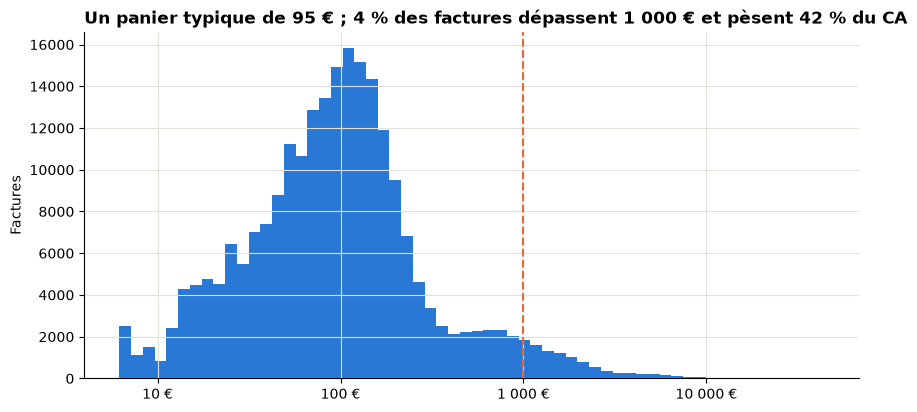

In [19]:
invoice_totals = sales.groupby("invoice_id").line_total.sum()
b2b_invoices = invoice_totals[invoice_totals > B2B_INVOICE_THRESHOLD]

print(f"Panier médian : {invoice_totals.median():.0f} € | moyen : {invoice_totals.mean():.0f} € | "
      f"90e centile : {invoice_totals.quantile(0.9):.0f} € | 99e centile : {invoice_totals.quantile(0.99):.0f} €")
print(f"Factures > {B2B_INVOICE_THRESHOLD} € : {len(b2b_invoices) / len(invoice_totals):.1%} des factures, "
      f"{b2b_invoices.sum() / invoice_totals.sum():.0%} du CA")

figure, axis = matplotlib.pyplot.subplots()
axis.hist(numpy.log10(invoice_totals), bins=60, color=PRIMARY_COLOR)
axis.axvline(numpy.log10(B2B_INVOICE_THRESHOLD), color=ACCENT_COLOR, linestyle="--")
axis.set_xticks([1, 2, 3, 4], ["10 €", "100 €", "1 000 €", "10 000 €"])
axis.set_ylabel("Factures")
axis.set_title("Un panier typique de 95 € ; 4 % des factures dépassent 1 000 € et pèsent 42 % du CA")
matplotlib.pyplot.show()

Le panier est très asymétrique. La masse des factures se situe entre 20 et 200 €, mais une poche de grosses factures (plus de 1 000 €) représente 4 % des commandes et 42 % du CA. Ces clients achètent en volume, régulièrement : tout indique une clientèle professionnelle (revendeurs, instituts) mélangée aux particuliers. Ce mélange est une limite à garder en tête pour la segmentation : un « Champion » peut être un B2B.

### Distribution de la fréquence d'achat

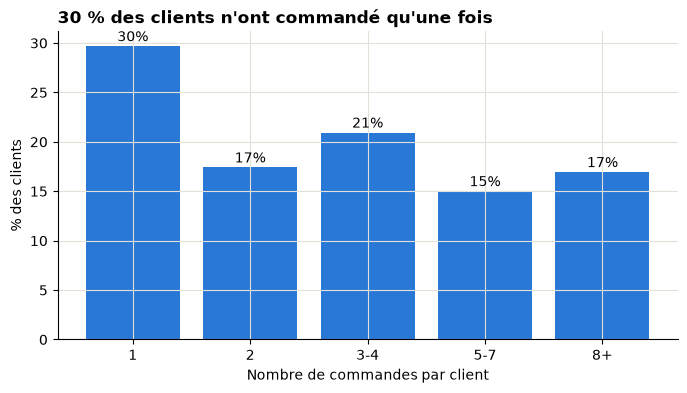

In [20]:
frequency_distribution = pandas.cut(
    customer_profile.n_orders, FREQUENCY_BINS, labels=["1", "2", "3-4", "5-7", "8+"]
).value_counts(normalize=True).sort_index()

figure, axis = matplotlib.pyplot.subplots(figsize=(8, 4))
axis.bar(frequency_distribution.index.astype(str), frequency_distribution * 100, color=PRIMARY_COLOR)
for position, value in enumerate(frequency_distribution):
    axis.text(position, value * 100 + 0.5, f"{value:.0%}", ha="center")
axis.set_xlabel("Nombre de commandes par client")
axis.set_ylabel("% des clients")
axis.set_title("30 % des clients n'ont commandé qu'une fois")
matplotlib.pyplot.show()

### Concentration du chiffre d'affaires (loi de Pareto)

22.8% des clients génèrent 80 % du CA identifié
Les 20 % de clients les plus dépensiers génèrent 78% du CA


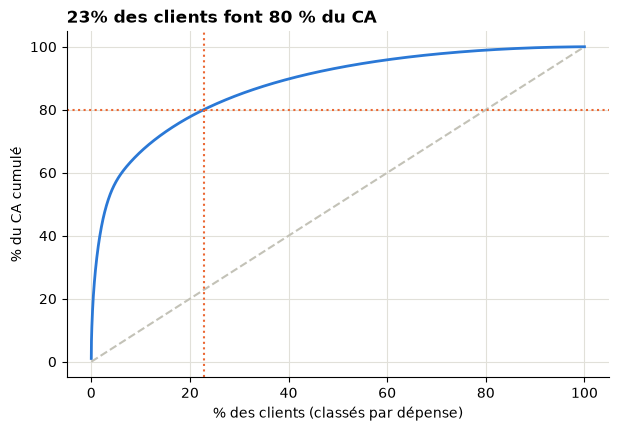

In [21]:
ranked = customer_profile.total_spent.sort_values(ascending=False)
cumulative_share = ranked.cumsum() / ranked.sum()
customer_share = numpy.arange(1, len(ranked) + 1) / len(ranked)
pareto_share = customer_share[(cumulative_share <= PARETO_THRESHOLD).sum()]
top_20_share = cumulative_share.iloc[int(len(ranked) * 0.2)]

print(f"{pareto_share:.1%} des clients génèrent 80 % du CA identifié")
print(f"Les 20 % de clients les plus dépensiers génèrent {top_20_share:.0%} du CA")

figure, axis = matplotlib.pyplot.subplots(figsize=(7, 4.5))
axis.plot(customer_share * 100, cumulative_share * 100, color=PRIMARY_COLOR, linewidth=2)
axis.plot([0, 100], [0, 100], color=MUTED_COLOR, linestyle="--")
axis.axhline(80, color=ACCENT_COLOR, linestyle=":")
axis.axvline(pareto_share * 100, color=ACCENT_COLOR, linestyle=":")
axis.set_xlabel("% des clients (classés par dépense)")
axis.set_ylabel("% du CA cumulé")
axis.set_title(f"{pareto_share:.0%} des clients font 80 % du CA")
matplotlib.pyplot.show()

La concentration est plus forte que la règle 80/20 : moins d'un quart des clients fait 80 % du CA. Un programme ciblé sur ce noyau protège l'essentiel du revenu, mais il faut vérifier au TP2 à quel point ce noyau est composé de clients B2B.

### Saisonnalité

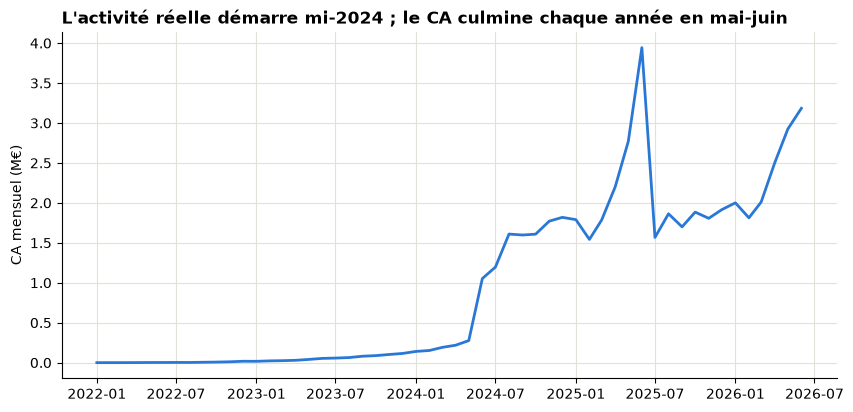

Mois les plus forts :
invoice_date
2025-06   3.94
2026-06   3.18
2026-05   2.92
2025-05   2.77
2026-04   2.50
Freq: M, Name: M€, dtype: float64


In [22]:
monthly_revenue = sales.groupby(sales.invoice_date.dt.to_period("M")).line_total.sum()
full_years = sales[sales.invoice_date >= "2024-07-01"]
month_profile = full_years.groupby(full_years.invoice_date.dt.month).line_total.sum()
month_profile = month_profile / month_profile.sum() * 100

figure, axis = matplotlib.pyplot.subplots()
axis.plot(monthly_revenue.index.to_timestamp(), monthly_revenue / 1e6, color=PRIMARY_COLOR, linewidth=2)
axis.set_ylabel("CA mensuel (M€)")
axis.set_title("L'activité réelle démarre mi-2024 ; le CA culmine chaque année en mai-juin")
matplotlib.pyplot.show()

print("Mois les plus forts :")
print((monthly_revenue.sort_values(ascending=False).head(5) / 1e6).round(2).rename("M€"))

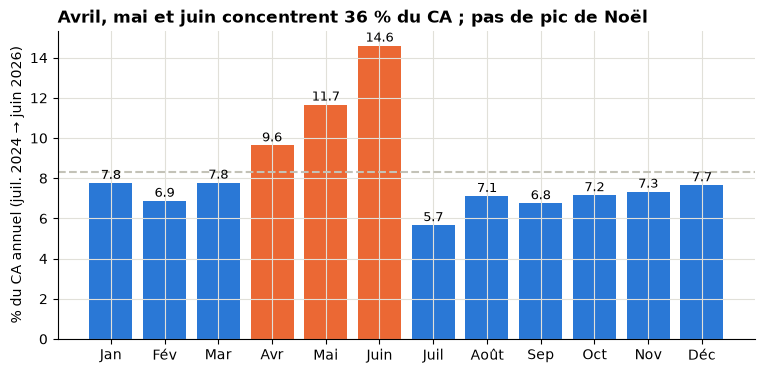

In [23]:
month_names = ["Jan", "Fév", "Mar", "Avr", "Mai", "Juin", "Juil", "Août", "Sep", "Oct", "Nov", "Déc"]
colors = [ACCENT_COLOR if month in (4, 5, 6) else PRIMARY_COLOR for month in month_profile.index]

figure, axis = matplotlib.pyplot.subplots(figsize=(9, 4))
axis.bar(month_names, month_profile, color=colors)
axis.axhline(100 / 12, color=MUTED_COLOR, linestyle="--")
for position, value in enumerate(month_profile):
    axis.text(position, value + 0.2, f"{value:.1f}", ha="center", fontsize=9)
axis.set_ylabel("% du CA annuel (juil. 2024 → juin 2026)")
axis.set_title("Avril, mai et juin concentrent 36 % du CA ; pas de pic de Noël")
matplotlib.pyplot.show()

Deux lectures :

- **Avant juin 2024, il n'y a quasiment rien** : le CRM n'a pas d'historique exploitable avant cette date. Les analyses de tendance portent donc sur deux années pleines.
- **Le pic est printanier, pas hivernal.** Avril, mai et juin font plus d'un tiers du CA annuel, avec un sommet en juin (près de 15 % de l'année) suivi d'un creux en juillet. Noël ne se voit pas. Pour les campagnes, cela signifie que l'effort marketing doit être concentré sur mars-avril (en amont du pic) et que juillet-septembre est la période creuse à animer, plutôt que novembre-décembre. Le pic de juin 2025 (3,9 M€, record absolu) mérite d'être expliqué par le métier : lancement produit, promotion exceptionnelle ou saisonnalité « fête des mères + préparation de l'été ».

### Géographie

In [24]:
geography = customer_profile.groupby("country").agg(
    clients=("total_spent", "size"),
    revenue=("total_spent", "sum"),
    avg_basket=("avg_basket", "median"),
    orders_per_customer=("n_orders", "mean"),
)
geography["clients (%)"] = geography.clients / geography.clients.sum() * 100
geography["CA (%)"] = geography.revenue / geography.revenue.sum() * 100
geography.sort_values("clients", ascending=False).head(10)[
    ["clients", "clients (%)", "CA (%)", "avg_basket", "orders_per_customer"]
]

,clients,clients (%),CA (%),avg_basket,orders_per_customer
country,,,,,
France,44898,91.27,90.90,78.18,4.40
Germany,903,1.84,1.97,82.41,4.79
United Kingdom,744,1.51,1.62,79.42,4.62
Spain,282,0.57,0.44,74.93,3.24
Portugal,206,0.42,0.32,77.56,3.46
Belgium,202,0.41,0.43,81.48,5.36
Switzerland,184,0.37,0.36,80.75,3.77
Sweden,162,0.33,0.17,75.28,2.60
Netherlands,160,0.33,0.48,74.79,3.98


**Biais géographique assumé.** 91 % des clients identifiés sont en France, et aucun autre pays ne dépasse 2 %. Les comportements d'achat varient peu avec la géographie : le panier médian est quasi identique partout (entre 75 et 82 €), seule la fréquence bouge un peu (5,4 commandes par client en Belgique contre 2,6 en Suède), et sur quelques centaines de clients ces écarts restent fragiles. Conséquence pour la suite : les segments RFM décriront le client français ; les seuils par quintile seront calibrés sur lui. Toute recommandation « export » devra être formulée comme hypothèse, pas comme résultat.

### Relations entre variables

recency_days x total_spent : Pearson -0.12, Spearman -0.44
n_orders x avg_basket : Pearson +0.08, Spearman +0.13


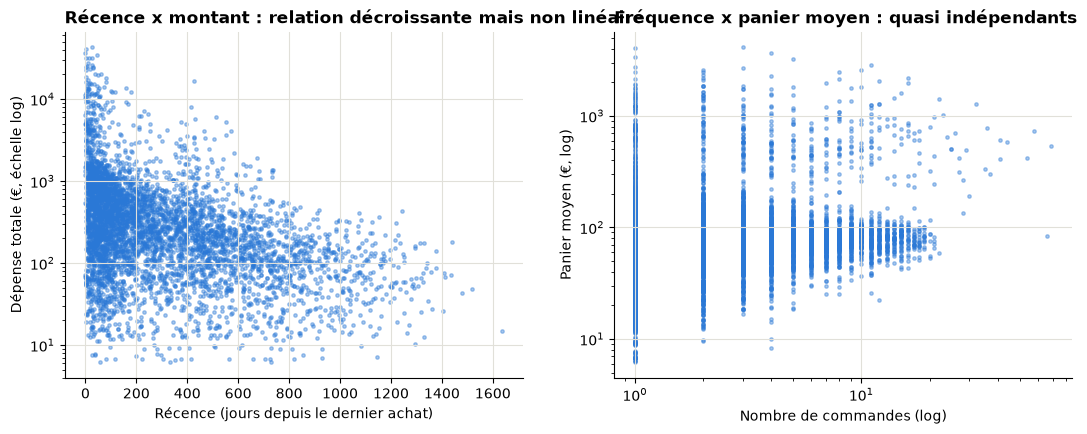

In [25]:
def correlations(dataset: pandas.DataFrame, first: str, second: str) -> str:
    pearson = dataset[[first, second]].corr().iloc[0, 1]
    spearman = dataset[[first, second]].corr(method="spearman").iloc[0, 1]
    return f"{first} x {second} : Pearson {pearson:+.2f}, Spearman {spearman:+.2f}"


print(correlations(customer_profile, "recency_days", "total_spent"))
print(correlations(customer_profile, "n_orders", "avg_basket"))

sample = customer_profile.sample(SCATTER_SAMPLE_SIZE, random_state=RANDOM_STATE)
figure, axes = matplotlib.pyplot.subplots(1, 2, figsize=(13, 4.5))
axes[0].scatter(sample.recency_days, sample.total_spent, s=6, alpha=0.4, color=PRIMARY_COLOR)
axes[0].set_yscale("log")
axes[0].set_xlabel("Récence (jours depuis le dernier achat)")
axes[0].set_ylabel("Dépense totale (€, échelle log)")
axes[0].set_title("Récence x montant : relation décroissante mais non linéaire")
axes[1].scatter(sample.n_orders, sample.avg_basket, s=6, alpha=0.4, color=PRIMARY_COLOR)
axes[1].set_xscale("log")
axes[1].set_yscale("log")
axes[1].set_xlabel("Nombre de commandes (log)")
axes[1].set_ylabel("Panier moyen (€, log)")
axes[1].set_title("Fréquence x panier moyen : quasi indépendants")
matplotlib.pyplot.show()

- **Récence × montant : la relation n'est pas linéaire.** Le coefficient de Pearson est faible (−0,12) mais le Spearman est nettement plus fort (−0,44) : le lien existe, il est monotone, mais pas proportionnel. Le nuage le montre : les clients très récents couvrent toute la gamme de dépense, alors qu'au-delà d'un an d'inactivité les gros montants disparaissent. Autrement dit, la récence est un bon filtre de risque, pas un prédicteur de valeur.
- **Fréquence × panier moyen : les clients fréquents ne dépensent pas plus par visite.** Corrélation proche de zéro. Fréquence et panier sont deux leviers indépendants : on peut travailler l'un sans l'autre.
- **Segments visibles à l'œil nu** : une bande dense de clients à moins de 100 jours de récence (actifs), un nuage épars au-delà de 400 jours (dormants), et une poche de clients à très forte dépense sur toute la plage de récence (profils B2B). Le RFM devrait les retrouver.

### Catégories de produits

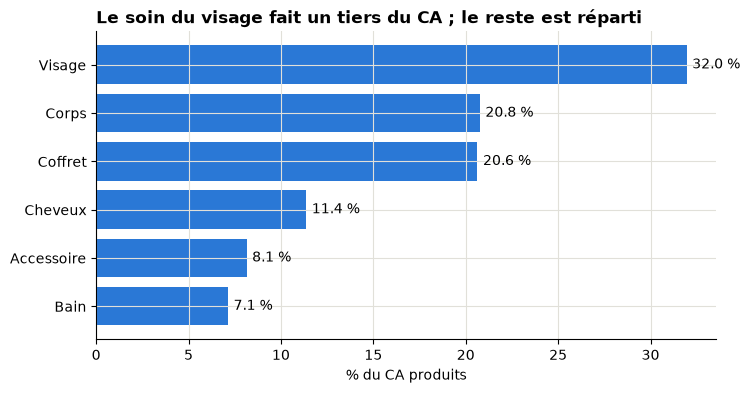

In [26]:
category_share = sales.groupby("category").line_total.sum().sort_values(ascending=False)
category_share = category_share / category_share.sum() * 100

figure, axis = matplotlib.pyplot.subplots(figsize=(8, 4))
axis.barh(category_share.index[::-1], category_share[::-1], color=PRIMARY_COLOR)
for position, value in enumerate(category_share[::-1]):
    axis.text(value + 0.3, position, f"{value:.1f} %", va="center")
axis.set_xlabel("% du CA produits")
axis.set_title("Le soin du visage fait un tiers du CA ; le reste est réparti")
matplotlib.pyplot.show()

Le Visage domine sans écraser (un tiers du CA), suivi de Corps et Coffret autour de 20 % chacun. La répartition est plutôt équilibrée : il n'y a pas de dépendance à une seule gamme. Le poids des coffrets est à relier à la saisonnalité (cadeaux de printemps). Ce tableau sert de référence au TP2 pour tester si certains segments ont une affinité produit.

### Données zero-party

In [27]:
fill_rates = customer_profile[ZERO_PARTY_COLUMNS].notna().mean() * 100
responders = customer_profile[ZERO_PARTY_COLUMNS].notna().any(axis=1)

print(fill_rates.round(1).rename("taux de remplissage (%)"), end="\n\n")
print(f"Clients ayant renseigné au moins un champ : {responders.mean():.1%}")
customer_profile.groupby(responders.rename("a répondu au quiz")).agg(
    clients=("total_spent", "size"),
    n_orders=("n_orders", "mean"),
    total_spent=("total_spent", "median"),
    recency_days=("recency_days", "median"),
)

declared_preference   38.00
age_bracket           42.70
life_stage            22.50
urban_density         19.80
Name: taux de remplissage (%), dtype: float64

Clients ayant renseigné au moins un champ : 78.0%


,clients,n_orders,total_spent,recency_days
a répondu au quiz,,,,
False,10833,4.38,244.02,212.00
True,38357,4.37,243.04,206.00


Les taux de remplissage (entre 20 % et 43 % selon le champ) sont cohérents avec une donnée zero-party : elle est déclarée volontairement, via un quiz de bienvenue, donc partielle par nature. Les champs les plus intimes ou les moins « utiles » pour le client (situation de vie, densité urbaine) sont les moins remplis. Point à retenir : les répondants au quiz ne se distinguent pas des autres (même nombre de commandes, même dépense médiane, même récence). Le quiz n'est donc pas un marqueur d'engagement, et la préférence déclarée ne prédit pas le comportement d'achat. Elle servira à personnaliser le message, pas à cibler.

## 1.6 Hypothèses marketing à tester avec la segmentation

1. **Je suppose que** la concentration du CA (23 % des clients font 80 % du CA) et la poche de factures > 1 000 € **impliquent** l'existence d'un noyau de clients à comportement professionnel, **ce qui suggère** de les isoler dans un segment dédié avec un traitement commercial (compte pro, tarif volume) plutôt que des campagnes grand public.
2. **Je suppose que** les 30 % de clients à commande unique **impliquent** une faible conversion au second achat, **ce qui suggère** une séquence d'onboarding dans les 30 jours (échantillon, offre de réassort) mesurée par le taux de 2e commande.
3. **Je suppose que** le pic avril-juin et le creux de juillet **impliquent** un achat saisonnier (cadeaux, préparation de l'été), **ce qui suggère** d'avancer le budget de campagne sur mars-avril et de tester une animation estivale pour lisser le creux.
4. **Je suppose que** la relation non linéaire entre récence et montant **implique** que des clients de forte valeur basculent dans l'inactivité au-delà d'un an, **ce qui suggère** un segment « à risque » déclenché sur la récence avec une relance avant le 12e mois.
5. **Je suppose que** l'indépendance entre réponses au quiz et comportement d'achat **implique** que la préférence déclarée ne sert pas à cibler mais à personnaliser, **ce qui suggère** de tester, sur un même segment RFM, un email personnalisé par préférence déclarée contre un email générique, et de pousser le quiz dès l'onboarding des nouveaux clients.

---
# TP2 — Segmentation RFM

## 2.1 Features RFM

La date de référence est le **snapshot** : la dernière date observée dans les ventes nettoyées (et non la date du jour, puisque les données s'arrêtent avant). Pour chaque client identifié :

- **Récence** : jours entre son dernier achat et le snapshot ;
- **Fréquence** : nombre de factures distinctes ;
- **Montant** : somme des `line_total` des lignes de vente (retours exclus, cf. TP1) ;
- enrichissements : panier moyen et ancienneté.

In [28]:
rfm = customer_profile.rename(columns={
    "recency_days": "recency", "n_orders": "frequency", "total_spent": "monetary",
}).copy()

print(f"Snapshot : {snapshot_date.date()} | {len(rfm):,} clients")
rfm[["recency", "frequency", "monetary", "avg_basket", "tenure_days"]].describe(percentiles=[0.2, 0.4, 0.6, 0.8]).T

Snapshot : 2026-06-30 | 49,190 clients


,count,mean,std,min,20%,40%,60%,80%,max
recency,"49,190.00",312.07,295.39,0.00,56.00,136.00,308.00,561.00,"1,635.00"
frequency,"49,190.00",4.38,5.74,1.00,1.00,2.00,4.00,7.00,373.00
monetary,"49,190.00",812.99,"4,161.09",6.18,80.72,175.41,336.64,700.19,"416,423.63"
avg_basket,"49,190.00",154.85,307.22,6.18,48.14,69.15,88.80,127.59,"9,876.54"
tenure_days,"49,190.00",539.15,299.08,0.00,248.80,471.00,630.00,769.00,"1,635.00"


## 2.2 Scores RFM

Récence et montant sont découpés en **quintiles** (5 = meilleur). Pour la fréquence, les quintiles ne fonctionnent pas : 30 % des clients ont exactement une commande et le quintile 40 % tombe sur deux commandes. Un découpage par rang aurait réparti au hasard les clients à une commande entre les scores 1 et 2. On fixe donc des **paliers manuels** lisibles par le métier, calés sur les quantiles observés : 1 commande, 2, 3-4, 5-7, 8 et plus.

In [29]:
rfm["r_score"] = pandas.qcut(rfm.recency, 5, labels=list(reversed(SCORE_LABELS))).astype(int)
rfm["m_score"] = pandas.qcut(rfm.monetary, 5, labels=SCORE_LABELS).astype(int)
rfm["f_score"] = pandas.cut(rfm.frequency, FREQUENCY_BINS, labels=SCORE_LABELS).astype(int)
rfm["rfm_code"] = rfm.r_score.astype(str) + rfm.f_score.astype(str) + rfm.m_score.astype(str)

thresholds = pandas.DataFrame({
    "récence (jours, seuils de quintile)": rfm.recency.quantile([0.2, 0.4, 0.6, 0.8]).values,
    "montant (€, seuils de quintile)": rfm.monetary.quantile([0.2, 0.4, 0.6, 0.8]).values,
    "fréquence (quantiles observés)": rfm.frequency.quantile([0.2, 0.4, 0.6, 0.8]).values,
}, index=["20 %", "40 %", "60 %", "80 %"])
thresholds

,"récence (jours, seuils de quintile)","montant (€, seuils de quintile)",fréquence (quantiles observés)
20 %,56.00,80.72,1.00
40 %,136.00,175.41,2.00
60 %,308.00,336.64,4.00
80 %,561.00,700.19,7.00


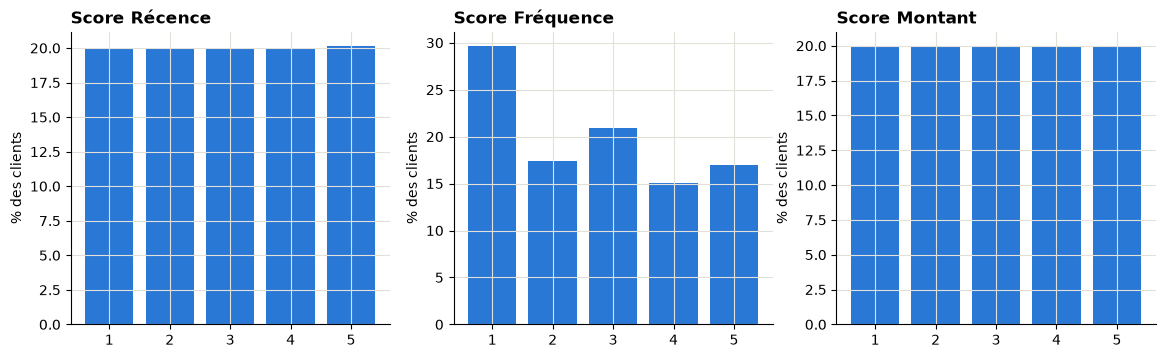

In [30]:
figure, axes = matplotlib.pyplot.subplots(1, 3, figsize=(14, 3.8))
for axis, column, label in zip(axes, ["r_score", "f_score", "m_score"], ["Récence", "Fréquence", "Montant"]):
    distribution = rfm[column].value_counts(normalize=True).sort_index() * 100
    axis.bar(distribution.index.astype(str), distribution, color=PRIMARY_COLOR)
    axis.set_title(f"Score {label}")
    axis.set_ylabel("% des clients")
matplotlib.pyplot.show()

Récence et montant sont bien équilibrés (20 % par score). La fréquence ne l'est pas, et c'est voulu : un score 1 signifie exactement « une seule commande », ce qui est actionnable (relance second achat), alors qu'un quintile artificiel ne l'aurait pas été.

## 2.3 Les trois cas extrêmes demandés

In [31]:
total_monetary = rfm.monetary.sum()
champions_555 = rfm[rfm.rfm_code == "555"]
at_risk = rfm[(rfm.r_score <= 2) & (rfm.m_score >= 4)]
lost_111 = rfm[rfm.rfm_code == "111"]

pandas.DataFrame({
    "clients": [len(champions_555), len(at_risk), len(lost_111)],
    "part de la base (%)": [len(group) / len(rfm) * 100 for group in (champions_555, at_risk, lost_111)],
    "part du CA (%)": [group.monetary.sum() / total_monetary * 100 for group in (champions_555, at_risk, lost_111)],
    "récence médiane (j)": [group.recency.median() for group in (champions_555, at_risk, lost_111)],
}, index=["Champions (555 exact)", "À risque (R ≤ 2 et M ≥ 4)", "Perdus (111 exact)"])

,clients,part de la base (%),part du CA (%),récence médiane (j)
Champions (555 exact),2926,5.95,41.34,26.00
À risque (R ≤ 2 et M ≥ 4),3744,7.61,9.68,446.00
Perdus (111 exact),3659,7.44,0.38,797.00


- **Champions 555** : environ 6 % de la base, mais plus de 40 % du CA. Ce sont les clients à protéger en priorité.
- **À risque** : des clients qui étaient dans les 40 % les plus dépensiers et n'ont pas acheté depuis plus de 300 jours. Leur valeur historique justifie une relance personnalisée (offre sur leur catégorie favorite) avant qu'ils ne basculent en perdus.
- **Perdus 111** : une seule commande, petit montant, plus de 18 mois d'inactivité. Action : les sortir des campagnes payantes (retargeting, affiliation) et ne garder qu'un contact gratuit à faible fréquence (email trimestriel). Le coût de réactivation dépasserait leur valeur attendue.

Ces trois profils ne couvrent qu'un cinquième de la base. La suite construit des règles par plage pour couvrir le reste.

## 2.4 Segmentation par règles

Huit segments, définis par des plages sur les trois scores, appliqués dans l'ordre (le premier critère vérifié l'emporte). Les seuils sont placés sur des ruptures lisibles : R ≥ 4 = acheté dans les 4 derniers mois environ, R ≤ 2 = plus de 300 jours sans achat, F ≥ 4 = au moins 5 commandes, M ≥ 4 = dans les 40 % de dépense les plus élevés.

| Ordre | Segment | Règle | Pourquoi ce seuil |
|---|---|---|---|
| 1 | **Champions** | R ≥ 4, F ≥ 4, M ≥ 4 | Les trois dimensions au-dessus de la médiane haute : meilleurs clients actuels. |
| 2 | **Fidèles** | R ≥ 3, F ≥ 4 | Achètent souvent et encore récemment, mais avec des paniers plus modestes que les Champions. |
| 3 | **Gros paniers occasionnels** | R ≥ 3, M ≥ 4 | Forte dépense avec peu de commandes : profil cadeau ou B2B ponctuel. |
| 4 | **Nouveaux** | R ≥ 4, F = 1 | Une seule commande, très récente : l'onboarding se joue maintenant. |
| 5 | **Prometteurs** | R ≥ 3 (reste) | Actifs, 2 à 4 commandes, dépense moyenne : le vivier des futurs Fidèles. |
| 6 | **À risque** | R ≤ 2 et (F ≥ 4 ou M ≥ 4) | Valeur historique forte, inactifs depuis plus de 300 jours. |
| 7 | **Perdus** | R = 1, F ≤ 2, M ≤ 2 | Plus de 18 mois d'inactivité, peu de commandes, faible dépense. |
| 8 | **Endormis** | R ≤ 2 (reste) | Inactifs à valeur moyenne : réactivables à bas coût. |

In [32]:
def assign_segments(scores: pandas.DataFrame) -> pandas.Series:
    r, f, m = scores.r_score, scores.f_score, scores.m_score
    rules = [
        ((r >= 4) & (f >= 4) & (m >= 4), "Champions"),
        ((r >= 3) & (f >= 4), "Fidèles"),
        ((r >= 3) & (m >= 4), "Gros paniers occasionnels"),
        ((r >= 4) & (f == 1), "Nouveaux"),
        (r >= 3, "Prometteurs"),
        ((r <= 2) & ((f >= 4) | (m >= 4)), "À risque"),
        ((r == 1) & (f <= 2) & (m <= 2), "Perdus"),
    ]
    conditions = [condition for condition, _ in rules]
    labels = [label for _, label in rules]
    return pandas.Series(numpy.select(conditions, labels, default="Endormis"), index=scores.index)


rfm["segment"] = pandas.Categorical(assign_segments(rfm), categories=SEGMENT_ORDER)

segment_summary = rfm.groupby("segment", observed=True).agg(
    clients=("monetary", "size"),
    recency=("recency", "median"),
    frequency=("frequency", "median"),
    monetary=("monetary", "median"),
    avg_basket=("avg_basket", "median"),
    tenure_days=("tenure_days", "median"),
    revenue=("monetary", "sum"),
)
segment_summary["clients (%)"] = segment_summary.clients / len(rfm) * 100
segment_summary["CA (%)"] = segment_summary.revenue / total_monetary * 100
segment_summary[["clients", "clients (%)", "CA (%)", "recency", "frequency", "monetary", "avg_basket", "tenure_days"]]

,clients,clients (%),CA (%),recency,frequency,monetary,avg_basket,tenure_days
segment,,,,,,,,
Champions,9352,19.01,61.73,53.00,9.00,843.34,85.08,583.00
Fidèles,4439,9.02,8.88,180.00,7.00,500.77,72.01,637.00
Gros paniers occasionnels,3400,6.91,10.30,91.00,3.00,556.26,222.10,327.00
Nouveaux,2978,6.05,0.61,62.00,1.00,63.83,63.83,62.00
Prometteurs,9378,19.06,3.89,141.00,2.00,161.18,65.78,256.00
À risque,4107,8.35,9.92,445.00,4.00,518.39,119.63,735.00
Endormis,8756,17.80,3.39,475.50,2.00,153.75,72.42,593.00
Perdus,6780,13.78,1.27,781.00,1.00,68.78,57.95,819.00


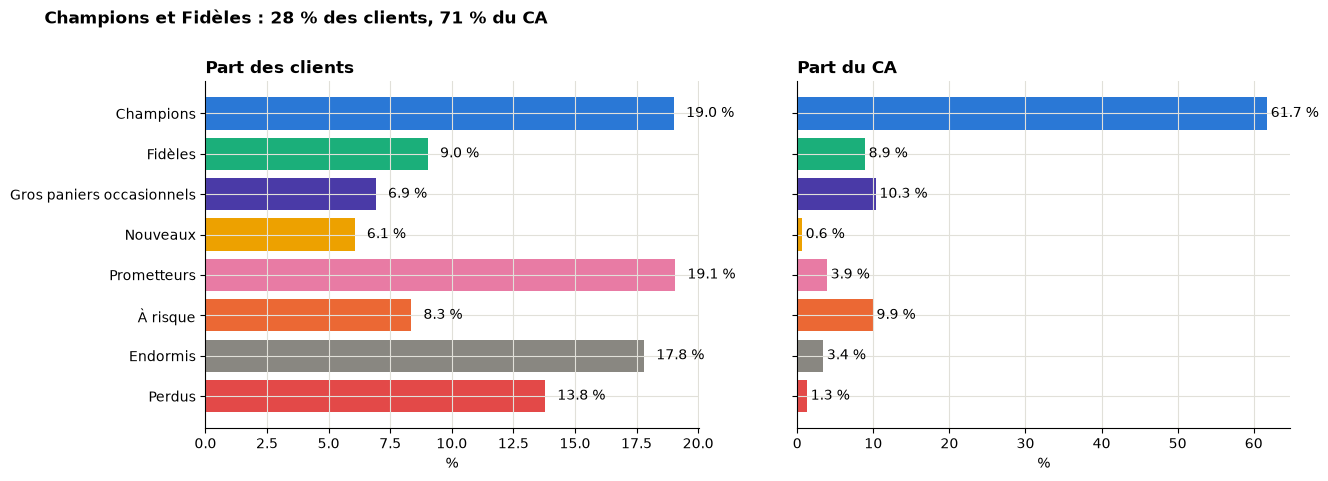

In [33]:
figure, axes = matplotlib.pyplot.subplots(1, 2, figsize=(14, 4.5), sharey=True)
colors = [SEGMENT_COLORS[segment] for segment in segment_summary.index]
for axis, column, title in zip(axes, ["clients (%)", "CA (%)"], ["Part des clients", "Part du CA"]):
    values = segment_summary[column]
    axis.barh(segment_summary.index[::-1], values[::-1], color=colors[::-1])
    for position, value in enumerate(values[::-1]):
        axis.text(value + 0.5, position, f"{value:.1f} %", va="center")
    axis.set_title(title)
    axis.set_xlabel("%")
figure.suptitle("Champions et Fidèles : 28 % des clients, 71 % du CA", x=0.01, y=1.04, ha="left", fontweight="bold")
matplotlib.pyplot.show()

## 2.5 Matrice RFM et nuage récence × montant

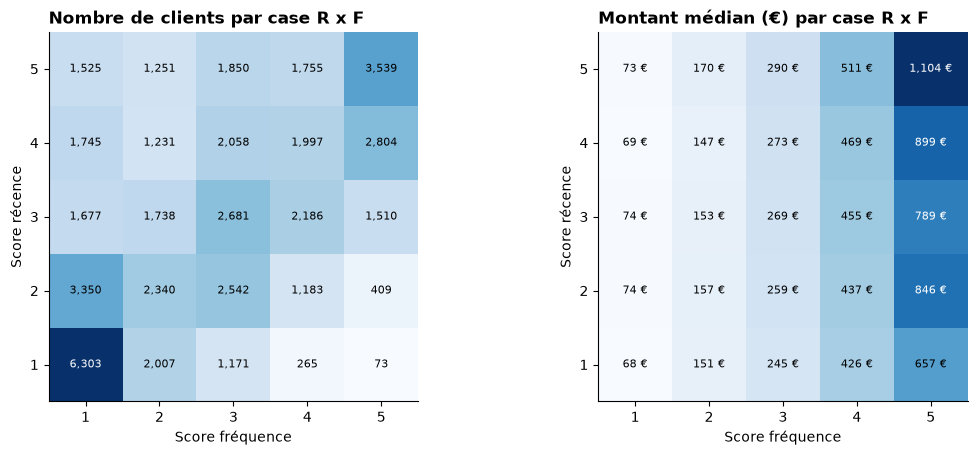

In [34]:
rfm_matrix_counts = rfm.pivot_table(index="r_score", columns="f_score", values="monetary", aggfunc="size")
rfm_matrix_monetary = rfm.pivot_table(index="r_score", columns="f_score", values="monetary", aggfunc="median")

figure, axes = matplotlib.pyplot.subplots(1, 2, figsize=(13, 4.8))
for axis, matrix, title, unit in zip(
    axes, [rfm_matrix_counts, rfm_matrix_monetary],
    ["Nombre de clients par case R x F", "Montant médian (€) par case R x F"], ["{:,.0f}", "{:,.0f} €"],
):
    image = axis.imshow(matrix.sort_index(ascending=False), cmap="Blues")
    axis.set_xticks(range(5), matrix.columns)
    axis.set_yticks(range(5), matrix.sort_index(ascending=False).index)
    axis.set_xlabel("Score fréquence")
    axis.set_ylabel("Score récence")
    axis.set_title(title)
    axis.grid(False)
    for row, r_value in enumerate(matrix.sort_index(ascending=False).index):
        for column, f_value in enumerate(matrix.columns):
            value = matrix.loc[r_value, f_value]
            axis.text(column, row, unit.format(value), ha="center", va="center", fontsize=8,
                      color="white" if value > matrix.values.max() * 0.6 else "black")
matplotlib.pyplot.show()

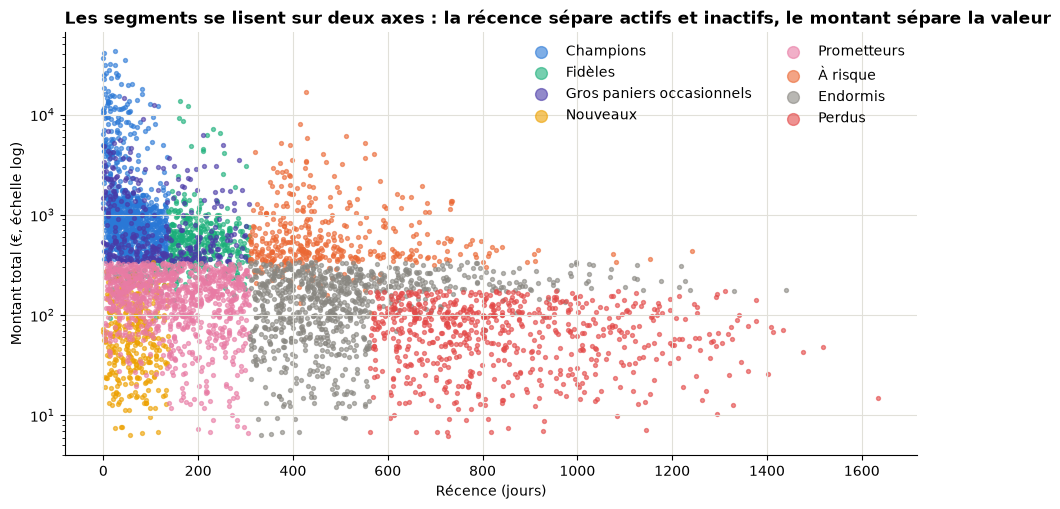

In [35]:
sample = rfm.sample(SCATTER_SAMPLE_SIZE, random_state=RANDOM_STATE)

figure, axis = matplotlib.pyplot.subplots(figsize=(11, 5.5))
for segment in SEGMENT_ORDER:
    points = sample[sample.segment == segment]
    axis.scatter(points.recency, points.monetary, s=8, alpha=0.6, color=SEGMENT_COLORS[segment], label=segment)
axis.set_yscale("log")
axis.set_xlabel("Récence (jours)")
axis.set_ylabel("Montant total (€, échelle log)")
axis.set_title("Les segments se lisent sur deux axes : la récence sépare actifs et inactifs, le montant sépare la valeur")
axis.legend(markerscale=3, frameon=False, ncol=2)
matplotlib.pyplot.show()

La matrice confirme le point de vigilance du TP : la relation récence × valeur n'est pas linéaire. À fréquence égale, le montant médian est presque le même quelle que soit la récence : un client inactif depuis deux ans qui avait 8 commandes vaut autant qu'un client actif à 8 commandes. C'est la fréquence qui porte la valeur ; la récence dit seulement si cette valeur est encore vivante. Les cases R = 1 ou 2 avec F = 5 (anciens très fidèles aujourd'hui inactifs) sont peu peuplées mais ont un montant médian élevé : c'est le cœur du segment « À risque ». Un score global additionné (R + F + M) aurait noyé cette information.

## 2.6 Profil des segments

In [36]:
rfm["is_france"] = rfm.country == "France"
rfm["is_b2b_like"] = rfm.avg_basket > B2B_INVOICE_THRESHOLD

profile = rfm.groupby("segment", observed=True).agg(
    clients=("monetary", "size"),
    france=("is_france", "mean"),
    tenure_days=("tenure_days", "median"),
    b2b_like=("is_b2b_like", "mean"),
)
profile["france (%)"] = profile.france * 100
profile["panier moyen > 1 000 € (%)"] = profile.b2b_like * 100
profile["pays n°2"] = rfm[~rfm.is_france].groupby("segment", observed=True).country.agg(lambda s: s.value_counts().index[0])
profile[["clients", "france (%)", "pays n°2", "tenure_days", "panier moyen > 1 000 € (%)"]]

,clients,france (%),pays n°2,tenure_days,panier moyen > 1 000 € (%)
segment,,,,,
Champions,9352,91.52,Germany,583.00,4.39
Fidèles,4439,91.48,Germany,637.00,0.92
Gros paniers occasionnels,3400,89.38,Germany,327.00,13.06
Nouveaux,2978,88.62,United Kingdom,62.00,0.00
Prometteurs,9378,89.97,Germany,256.00,0.00
À risque,4107,93.52,Germany,735.00,8.64
Endormis,8756,91.82,Germany,593.00,0.00
Perdus,6780,92.65,Germany,819.00,0.00


In [37]:
category_by_segment = customer_sales.join(rfm.segment, on="customer_id").pivot_table(
    index="segment", columns="category", values="line_total", aggfunc="sum", observed=True,
)
category_by_segment = category_by_segment.div(category_by_segment.sum(axis=1), axis=0) * 100
category_by_segment.round(1)

category,Accessoire,Bain,Cheveux,Coffret,Corps,Visage
segment,,,,,,
Champions,8.20,7.00,11.30,20.90,20.70,32.00
Fidèles,8.50,7.30,11.10,20.20,20.70,32.30
Gros paniers occasionnels,7.50,6.90,11.30,23.10,20.40,30.90
Nouveaux,7.70,7.40,11.60,19.90,21.60,31.70
Prometteurs,9.10,8.30,12.40,15.90,22.70,31.60
À risque,7.90,6.80,10.60,22.00,20.30,32.50
Endormis,8.40,7.50,11.50,19.60,20.90,32.10
Perdus,9.10,8.80,12.50,13.00,23.90,32.60


Lecture des profils :

- Tous les segments sont à plus de 90 % français : la géographie ne discrimine pas (biais de base, cf. TP1).
- **L'ancienneté distingue nettement** : les Champions et Fidèles sont là depuis plus d'un an et demi, les Nouveaux depuis quelques semaines, les Perdus sont d'anciens clients du démarrage.
- **Les Gros paniers occasionnels sont le segment le plus « B2B »** : 13 % y ont un panier moyen supérieur à 1 000 €, contre 9 % chez les À risque et 4 % chez les Champions. Les gros comptes inactifs se cachent donc dans les À risque : un argument de plus pour leur priorité.
- **Le mix produits varie peu d'un segment à l'autre** : le Visage reste en tête partout. Les coffrets pèsent un peu plus chez les occasionnels (logique cadeau). L'affinité produit n'est donc pas un critère de segmentation ici, mais un levier de personnalisation du message.

## 2.7 Fiches segments et priorisation

| Rang | Segment | Qui sont-ils | Potentiel | Risque | Action recommandée | Métrique de succès |
|---|---|---|---|---|---|---|
| **1** | **À risque** | Anciens bons clients (forte fréquence ou forte dépense), sans achat depuis plus de 300 jours. | Élevé : valeur historique prouvée, il suffit de les faire revenir. | Churn imminent : chaque mois sans action les rapproche des Perdus. | Relance personnalisée en 2 temps : email sur leur catégorie favorite, puis offre de retour (−15 %) si pas de réaction sous 15 jours. Retargeting ciblé sur ce seul segment. | Taux de réactivation à 60 jours (objectif 10 %). |
| **2** | **Champions** | Achètent souvent, récemment, beaucoup. Une partie sont des pros. | Très élevé : 62 % du CA pour 19 % des clients. À faire durer, pas à faire croître à tout prix. | Faible à court terme, mais la perte d'un Champion coûte 10 fois celle d'un Nouveau. | Programme VIP sans remise : avant-premières, échantillons, service dédié. Identifier les comptes pros et leur proposer une offre volume. **Exclure des promotions agressives** (ils achèteraient de toute façon). | Taux de rétention à 6 mois (objectif > 90 %), CA par Champion stable. |
| **3** | **Nouveaux** | Une seule commande, dans les 4 derniers mois. | Élevé mais incertain : 30 % de la base ne dépasse jamais la première commande. | Fort : sans second achat sous 90 jours, ils deviennent Endormis. | Séquence d'onboarding automatisée J+7 / J+30 / J+60 : conseils d'usage, quiz zero-party, offre de réassort au bon moment. | Taux de 2e commande à 90 jours (objectif 35 %). |
| **4** | **Prometteurs** | Actifs, 2 à 4 commandes, dépense moyenne. | Moyen à élevé : le vivier des futurs Fidèles. | Modéré. | Cross-sell vers une 2e catégorie, incitation au programme de fidélité, panier bonus à partir d'un seuil. | Passage en Fidèles à 6 mois, panier moyen. |
| **5** | **Fidèles** | Commandent souvent, récemment, paniers modestes. | Moyen : la fréquence est là, la marge de progression est sur le panier. | Faible. | Montée en gamme : coffrets, routines complètes, seuil de livraison offerte. Pas de remise générale. | Panier moyen (+10 %). |
| **6** | **Gros paniers occasionnels** | Peu de commandes mais très grosses : cadeau, événement ou pro ponctuel. | Élevé par commande, incertain en fréquence. | Modéré : difficile à prévoir. | Rappel calendaire avant le pic de printemps, offre « entreprise / cadeaux » dédiée. | Taux de réachat à 12 mois. |
| **7** | **Endormis** | Inactifs depuis plus de 300 jours, valeur moyenne. | Faible à moyen. | Déjà réalisé en partie. | Réactivation à coût nul uniquement (email, 1 fois par mois). Pas de média payant. | Taux de réouverture et de réactivation. |
| **8** | **Perdus** | Une ou deux commandes, petit montant, plus de 18 mois sans achat. | Faible. | Déjà perdus. | **Sortie des campagnes payantes** et du retargeting. Email trimestriel « on a changé », puis nettoyage de la base. | Coût marketing économisé. |

**Critère de chaque rang** : 1 = urgence × valeur (perte imminente de clients prouvés), 2 = valeur (protéger ce qui fait le CA), 3 = potentiel de croissance avec fenêtre d'action courte, 4-5 = potentiel de croissance sans urgence, 6 = valeur par commande mais faible prévisibilité, 7-8 = faible valeur : on économise plutôt qu'on investit.

**Cohérence budgétaire** : les rangs 1 à 3 reçoivent des actions personnalisées et du média payant ciblé ; les rangs 4 à 6 des automatisations et du contenu ; les rangs 7 et 8 ne coûtent rien ou libèrent du budget. L'ordre théorique se traduit bien en écarts de moyens réels.

In [38]:
segment_map = segment_summary[["clients", "clients (%)", "CA (%)", "recency", "frequency", "monetary"]].copy()
segment_map["priorité"] = segment_map.index.map({
    "À risque": 1, "Champions": 2, "Nouveaux": 3, "Prometteurs": 4,
    "Fidèles": 5, "Gros paniers occasionnels": 6, "Endormis": 7, "Perdus": 8,
})
segment_map = segment_map.sort_values("priorité")
segment_map.to_csv(SEGMENTS_FILE)
segment_map

,clients,clients (%),CA (%),recency,frequency,monetary,priorité
segment,,,,,,,
Champions,9352,19.01,61.73,53.00,9.00,843.34,2
Fidèles,4439,9.02,8.88,180.00,7.00,500.77,5
Gros paniers occasionnels,3400,6.91,10.30,91.00,3.00,556.26,6
Nouveaux,2978,6.05,0.61,62.00,1.00,63.83,3
Prometteurs,9378,19.06,3.89,141.00,2.00,161.18,4
À risque,4107,8.35,9.92,445.00,4.00,518.39,1
Endormis,8756,17.80,3.39,475.50,2.00,153.75,7
Perdus,6780,13.78,1.27,781.00,1.00,68.78,8


## 2.8 Pour aller plus loin : croiser un segment RFM avec le zero-party

On croise le segment **À risque** (priorité 1) avec la préférence déclarée, en comparant sa répartition à celle de l'ensemble des répondants. Un écart (lift) supérieur à 1 signifie que la préférence est sur-représentée dans le segment.

In [39]:
def zero_party_lift(segment: str, column: str) -> pandas.DataFrame:
    responders = rfm[rfm[column].notna()]
    base_share = responders[column].value_counts(normalize=True)
    segment_share = responders.loc[responders.segment == segment, column].value_counts(normalize=True)
    return pandas.DataFrame({
        "segment (%)": segment_share * 100,
        "base (%)": base_share * 100,
        "lift": segment_share / base_share,
        "répondants du segment": responders.loc[responders.segment == segment, column].value_counts(),
    }).sort_values("lift", ascending=False)


print(f"Répondants au champ declared_preference parmi les À risque : "
      f"{rfm.loc[rfm.segment == 'À risque', 'declared_preference'].notna().mean():.0%}")
zero_party_lift("À risque", "declared_preference")

Répondants au champ declared_preference parmi les À risque : 37%


,segment (%),base (%),lift,répondants du segment
declared_preference,,,,
Recherche vegan,15.22,14.29,1.06,229
Peau sensible,15.15,14.66,1.03,228
Anti-imperfections,14.82,14.42,1.03,223
Anti-âge,14.42,14.47,1.00,217
Sans parfum,13.49,13.99,0.96,203
Peau sèche,13.42,14.02,0.96,202
Peau mixte,13.49,14.15,0.95,203


In [40]:
zero_party_lift("Champions", "age_bracket")

,segment (%),base (%),lift,répondants du segment
age_bracket,,,,
45-54 ans,20.08,19.75,1.02,799
18-24 ans,20.63,20.45,1.01,821
35-44 ans,20.18,20.14,1.00,803
25-34 ans,19.70,19.95,0.99,784
55 ans et plus,19.40,19.70,0.99,772


**Résultat honnête : le croisement ne révèle pas de profil plus précis.** Les préférences déclarées des clients À risque sont réparties comme celles de la base (lifts entre 0,9 et 1,1), et il en va de même pour l'âge des Champions. Le RFM et le zero-party sont ici indépendants : le quiz ne dit pas *qui* va churner.

En revanche, il dit *quoi leur dire*. Pour les 37 % de clients À risque qui ont déclaré une préférence, la relance peut porter sur leur besoin déclaré (« votre routine peau sensible a évolué ») au lieu d'une offre générique. On passe d'un message RFM (« ça fait longtemps ») à un message produit personnalisé, sur le même canal email. Pour les 63 % restants, la relance générique reste la seule option, et c'est un argument pour pousser le quiz dès l'onboarding des Nouveaux.

## 2.9 Pour aller plus loin : et sur une base de 50 clients ?

Les quintiles n'ont pas de sens sur 50 clients : « 20 % » = 10 personnes, et un seul client déplacé change un seuil. Un auto-entrepreneur fixerait des paliers métier à la main, par exemple : Récence = acheté ce mois / ce trimestre / cette année / plus ; Fréquence = 1 / 2-3 / 4 et plus ; Montant = en dessous ou au-dessus de son panier moyen. Trois scores à 3 niveaux suffisent, et chaque client se nomme : c'est une liste à regarder, pas une distribution à découper.

---
# TP3 — KPIs de campagne et attribution

## 3.1 Les données de campagne

In [41]:
touchpoints = pandas.read_csv(TOUCHPOINTS_FILE, parse_dates=["timestamp"])
campaigns = pandas.read_csv(CAMPAIGNS_FILE, parse_dates=["start_date", "end_date"])
touchpoints["journey_type"] = touchpoints.journey_id.str.split("_").str[0]

journey_sizes = touchpoints.groupby("journey_id").size()
print(f"{len(touchpoints):,} touchpoints | {touchpoints.journey_id.nunique():,} parcours | "
      f"{touchpoints.customer_id.nunique():,} clients touchés")
print(f"Parcours convertis (conv_) : {(touchpoints.journey_type == 'conv').sum():,} touchpoints, "
      f"parcours sans conversion (exp_) : {(touchpoints.journey_type == 'exp').sum():,}")
print(f"Conversions : {touchpoints.converted.sum():,} (une par parcours converti)")
print(f"Touchpoints par parcours : moyenne {journey_sizes.mean():.1f}, médiane {journey_sizes.median():.0f}")
campaigns[["campaign_name", "primary_channel", "start_date", "end_date", "total_cost", "revenue", "n_conversions", "cpa", "roas"]]

1,080,897 touchpoints | 214,897 parcours | 49,054 clients touchés
Parcours convertis (conv_) : 357,768 touchpoints, parcours sans conversion (exp_) : 723,129
Conversions : 94,366 (une par parcours converti)
Touchpoints par parcours : moyenne 5.0, médiane 5


,campaign_name,primary_channel,start_date,end_date,total_cost,revenue,n_conversions,cpa,roas
0,Back_to_School,social,2025-08-09 23:22:22.554461652,2025-10-15 23:59:59.624507864,"159,256.41","725,541.50",13192,12.07,4.56
1,Black_Friday,display,2025-10-02 18:51:37.807091349,2025-12-27 23:59:37.789190263,"205,749.41","957,170.87",18777,10.96,4.65
2,Spring_Launch,display,2026-04-02 18:02:14.505881373,2026-06-29 23:59:25.975461263,"374,813.33","1,686,555.27",20372,18.40,4.50
3,Summer_Sale,display,2025-06-16 05:36:28.494713012,2025-08-22 23:58:58.285941573,"226,774.16","621,009.60",12714,17.84,2.74
4,Valentine,display,2026-02-07 14:52:39.479203239,2026-04-14 23:58:57.777460163,"247,465.96","853,184.79",15141,16.34,3.45
5,Winter_Promo,display,2025-12-14 23:13:04.314410780,2026-02-19 23:59:53.504774786,"133,949.00","716,632.64",14170,9.45,5.35


## 3.2 Relier les conversions aux factures et repérer les primo-achats

Chaque conversion référence un `invoice_id`. On le relie aux ventes nettoyées pour obtenir le revenu et la date de la facture, puis on compare cette date à la première commande du client. Le TP suggère `first_purchase` de `customers.csv` ; on l'applique, mais on sait depuis le TP1 que cette colonne est fausse. On calcule donc aussi le primo-achat avec la première facture réellement observée.

In [42]:
invoice_summary = sales.groupby("invoice_id").agg(
    invoice_revenue=("line_total", "sum"), invoice_date=("invoice_date", "min"),
)
conversions = touchpoints[touchpoints.converted == 1].copy()
conversions["invoice_id"] = conversions.invoice_id.astype("int64").astype(str)
conversions = conversions.join(invoice_summary, on="invoice_id")
conversions = conversions.join(customers.set_index("customer_id").first_purchase.rename("declared_first_purchase"), on="customer_id")
conversions = conversions.join(customer_profile.first_purchase.rename("observed_first_purchase"), on="customer_id")
conversions["is_new_customer_declared"] = conversions.invoice_date.dt.date == conversions.declared_first_purchase.dt.date
conversions["is_new_customer"] = conversions.invoice_date.dt.date == conversions.observed_first_purchase.dt.date

print(f"Conversions reliées à une facture : {conversions.invoice_revenue.notna().mean():.1%}")
print(f"Primo-achats selon customers.csv : {conversions.is_new_customer_declared.sum():,} "
      f"({conversions.is_new_customer_declared.mean():.1%} des conversions)")
print(f"Primo-achats selon la première facture observée : {conversions.is_new_customer.sum():,} "
      f"({conversions.is_new_customer.mean():.1%} des conversions)")

Conversions reliées à une facture : 99.9%
Primo-achats selon customers.csv : 1,747 (1.9% des conversions)
Primo-achats selon la première facture observée : 12,611 (13.4% des conversions)


Avec `customers.csv`, moins de 2 % des conversions seraient des primo-achats, ce qui donnerait des CAC absurdes (plusieurs milliers d'euros). Avec la première facture observée, 13 % des conversions sont des acquisitions, un ordre de grandeur crédible pour une marque qui travaille surtout sa base. **On retient la méthode observée** et on garde la version déclarée à titre de comparaison.

## 3.3 KPIs par canal

Définitions retenues (à figer, car un KPI mal défini est un KPI qu'on ne compare pas) :

- **CTR** = clics / touchpoints ;
- **Taux de conversion** = conversions / clics (une conversion est le touchpoint marqué `converted`) ;
- **CPA** = coût du canal / conversions attribuées au canal (dernier contact) ;
- **CAC** = coût du canal / primo-achats attribués au canal ;
- **ROAS** = revenu des factures converties sur le canal / coût du canal.

Le canal `direct` n'a aucun coût : CPA, CAC et ROAS n'y sont pas définis (on ne divise pas par zéro, on l'exclut du classement).

In [43]:
channel_kpis = touchpoints.groupby("channel").agg(
    touchpoints=("touchpoint_id", "size"), clicks=("click", "sum"), cost=("cost", "sum"),
)
channel_kpis = channel_kpis.join(conversions.groupby("channel").agg(
    conversions=("touchpoint_id", "size"),
    new_customers=("is_new_customer", "sum"),
    new_customers_declared=("is_new_customer_declared", "sum"),
    revenue=("invoice_revenue", "sum"),
)).fillna(0)
channel_kpis["ctr"] = channel_kpis.clicks / channel_kpis.touchpoints
channel_kpis["conversion_rate"] = channel_kpis.conversions / channel_kpis.clicks
channel_kpis["cpa"] = channel_kpis.cost / channel_kpis.conversions
channel_kpis["cac"] = channel_kpis.cost / channel_kpis.new_customers
channel_kpis["cac_declared"] = channel_kpis.cost / channel_kpis.new_customers_declared
channel_kpis["roas"] = channel_kpis.revenue / channel_kpis.cost
channel_kpis = channel_kpis.replace([numpy.inf, -numpy.inf], numpy.nan)
channel_kpis.loc[channel_kpis.cost == 0, ["cpa", "cac", "cac_declared", "roas"]] = numpy.nan
channel_kpis = channel_kpis.loc[CHANNEL_ORDER]

channel_kpis[["touchpoints", "clicks", "cost", "conversions", "new_customers", "revenue",
              "ctr", "conversion_rate", "cpa", "cac", "cac_declared", "roas"]]

,touchpoints,clicks,cost,conversions,new_customers,revenue,ctr,conversion_rate,cpa,cac,cac_declared,roas
channel,,,,,,,,,,,,
display,316530,142192,"1,482.10",0.00,0.00,0.00,0.45,0.00,NaN,NaN,NaN,0.00
social,315763,142089,"166,324.04",0.00,0.00,0.00,0.45,0.00,NaN,NaN,NaN,0.00
email,150733,75666,"2,263.28","14,355.00","1,838.00","2,624,888.44",0.50,0.19,0.16,1.23,8.84,"1,159.77"
retargeting,158102,83548,"1,897.65","22,563.00","3,078.00","4,490,554.42",0.53,0.27,0.08,0.62,4.30,"2,366.38"
affiliate,54516,44884,"1,128,776.74","26,979.00","3,673.00","5,354,369.80",0.82,0.60,41.84,307.32,"2,226.38",4.74
search_paid,41334,31548,"47,264.48","13,666.00","1,841.00","2,846,213.19",0.76,0.43,3.46,25.67,177.69,60.22
direct,43919,34441,0.00,"16,803.00","2,181.00","3,230,578.56",0.78,0.49,NaN,NaN,NaN,NaN


In [44]:
rankings = pandas.DataFrame({
    "CAC (↓)": channel_kpis.cac.rank(method="min"),
    "CPA (↓)": channel_kpis.cpa.rank(method="min"),
    "ROAS (↑)": channel_kpis.roas.rank(ascending=False, method="min"),
    "Taux de conversion (↑)": channel_kpis.conversion_rate.rank(ascending=False, method="min"),
}).astype("Int64")
rankings

,CAC (↓),CPA (↓),ROAS (↑),Taux de conversion (↑)
channel,,,,
display,<NA>,<NA>,5,6
social,<NA>,<NA>,5,6
email,2,2,2,5
retargeting,1,1,1,4
affiliate,4,4,4,1
search_paid,3,3,3,3
direct,<NA>,<NA>,<NA>,2


### Lecture du classement

**Le classement n'est pas le même selon la métrique, et c'est normal : chaque KPI répond à une question différente.**

- **Sur le CPA et le CAC**, email et retargeting écrasent tout : quelques centimes par conversion. Ils coûtent presque rien parce qu'ils s'adressent à des gens déjà connus (base email, visiteurs déjà venus). Ils ne créent pas la demande, ils la récoltent.
- **Sur le ROAS**, même ordre : les canaux pas chers ont mécaniquement un ROAS énorme. Le ROAS récompense le coût faible autant que le revenu élevé.
- **Sur le taux de conversion**, l'affiliation et le search payant passent devant : quand quelqu'un clique sur un lien de créatrice ou sur une annonce de recherche, il est déjà en intention d'achat. Mais l'affiliation est de loin le canal le plus cher (84 % du budget total), donc son CPA est le plus élevé des canaux payants.
- **Display et social sont absents ou derniers de chaque classement** : aucune conversion directe ne leur est attribuée, donc CPA et CAC sont indéfinis et le ROAS vaut zéro. Ce n'est pas une absence de performance, c'est une absence de mesure : ces canaux sont jugés ici sur le dernier contact alors qu'ils interviennent en début de parcours (voir 3.6). Les classer « derniers » sur ces KPIs serait une erreur de lecture ; il faut les évaluer sur les conversions assistées.
- **Direct** convertit bien et ne coûte rien, mais ce n'est pas un canal qu'on achète : c'est le résultat des autres.

### CAC vs CPA

Le CAC est systématiquement plus élevé que le CPA (même coût, moins de conversions au numérateur). Le ratio est d'environ 7 à 8 sur tous les canaux payants : 87 % des conversions sont du réachat. Lumina & Co dépense donc l'essentiel de son budget média sur des clients qu'elle connaît déjà. La colonne `cac_declared` montre ce qu'on aurait obtenu avec `first_purchase` de `customers.csv` : des valeurs 7 fois plus hautes encore, inexploitables.

## 3.4 Les revenus de `campaigns.csv` ne recoupent pas les factures

In [45]:
campaign_check = campaigns.set_index("campaign_name")[["total_cost", "revenue", "n_conversions", "roas", "primary_channel"]]
campaign_check = campaign_check.join(
    conversions.groupby("campaign_name").agg(revenue_invoices=("invoice_revenue", "sum"), conversions_touchpoints=("touchpoint_id", "size"))
).join(touchpoints.groupby("campaign_name").cost.sum().rename("cost_touchpoints"))
campaign_check["ratio revenu factures / revenu campaigns"] = campaign_check.revenue_invoices / campaign_check.revenue
campaign_check["roas_invoices"] = campaign_check.revenue_invoices / campaign_check.cost_touchpoints
campaign_check[["total_cost", "cost_touchpoints", "n_conversions", "conversions_touchpoints",
                "revenue", "revenue_invoices", "ratio revenu factures / revenu campaigns", "roas", "roas_invoices"]]

,total_cost,cost_touchpoints,n_conversions,conversions_touchpoints,revenue,revenue_invoices,ratio revenu factures / revenu campaigns,roas,roas_invoices
campaign_name,,,,,,,,,
Back_to_School,"159,256.41","159,256.41",13192,13192,"725,541.50","2,319,444.92",3.20,4.56,14.56
Black_Friday,"205,749.41","205,749.41",18777,18777,"957,170.87","3,332,308.21",3.48,4.65,16.20
Spring_Launch,"374,813.33","374,813.33",20372,20372,"1,686,555.27","5,431,444.25",3.22,4.50,14.49
Summer_Sale,"226,774.16","226,774.16",12714,12714,"621,009.60","2,127,500.20",3.43,2.74,9.38
Valentine,"247,465.96","247,465.96",15141,15141,"853,184.79","2,833,475.83",3.32,3.45,11.45
Winter_Promo,"133,949.00","133,949.00",14170,14170,"716,632.64","2,502,431.00",3.49,5.35,18.68


Coûts et nombre de conversions recoupent exactement. Le revenu, non : les factures reliées aux conversions valent **3,3 fois** le revenu déclaré dans `campaigns.csv`, avec un ratio stable d'une campagne à l'autre. `campaigns.csv` mesure donc autre chose (revenu incrémental estimé, marge, ou part attribuée à la campagne) sans que la définition soit documentée. Le classement des campagnes est le même avec les deux sources, mais les niveaux de ROAS ne le sont pas.

**Décision** : les KPIs par canal utilisent les factures (seule source disponible à cette maille) ; les comparaisons entre campagnes utilisent `campaigns.csv` ; la présentation au CMO mentionnera l'écart comme limite et demandera la définition du revenu au data engineer.

## 3.5 Que désigne `primary_channel` ?

In [46]:
by_campaign_channel = touchpoints.groupby(["campaign_name", "channel"]).agg(
    touchpoints=("touchpoint_id", "size"), cost=("cost", "sum"),
)
revenue_by_campaign_channel = conversions.groupby(["campaign_name", "channel"]).invoice_revenue.sum()
roas_by_campaign_channel = (revenue_by_campaign_channel / by_campaign_channel.cost).replace(numpy.inf, numpy.nan)

primary_check = campaigns.set_index("campaign_name")[["primary_channel"]].copy()
primary_check["canal le plus présent"] = by_campaign_channel.touchpoints.unstack().idxmax(axis=1)
primary_check["canal le plus coûteux"] = by_campaign_channel.cost.unstack().idxmax(axis=1)
primary_check["canal au meilleur ROAS"] = roas_by_campaign_channel.unstack().idxmax(axis=1)
cpa_by_campaign_channel = by_campaign_channel.cost.where(by_campaign_channel.cost > 0) / conversions.groupby(["campaign_name", "channel"]).size()
primary_check["canal au meilleur CPA"] = cpa_by_campaign_channel.unstack().idxmin(axis=1)
primary_check

,primary_channel,canal le plus présent,canal le plus coûteux,canal au meilleur ROAS,canal au meilleur CPA
campaign_name,,,,,
Back_to_School,social,social,affiliate,retargeting,retargeting
Black_Friday,display,display,affiliate,retargeting,retargeting
Spring_Launch,display,display,affiliate,retargeting,retargeting
Summer_Sale,display,display,affiliate,retargeting,retargeting
Valentine,display,display,affiliate,retargeting,retargeting
Winter_Promo,display,display,affiliate,email,email


`primary_channel` est le **canal le plus présent dans le parcours** (le plus grand nombre de touchpoints), c'est-à-dire le canal de diffusion principal de la campagne : display, et social pour la rentrée. Il n'arrive en tête sur aucune métrique de performance : le canal le plus coûteux est toujours l'affiliation, et les meilleurs CPA / ROAS sont toujours email ou retargeting. Lire `primary_channel` comme « le canal qui a marché » serait un contresens : c'est « le canal qu'on a le plus utilisé ».

## 3.6 Métriques de vanité

Prises isolément, trois colonnes de `touchpoints.csv` sont des métriques de vanité :

- **le nombre de touchpoints** : on peut en multiplier à l'infini en affichant plus de bannières ;
- **le nombre de clics** : un clic n'est pas une vente, et il se paie ;
- **le coût** : dépenser plus n'est pas un résultat.

Même **les conversions brutes** flattent : 94 000 conversions dont 87 % de réachat ne disent rien de l'acquisition. Ce qui les transforme en KPI, c'est le **ratio** : clics / touchpoints (CTR) mesure la pertinence du message, conversions / clics mesure la qualité du trafic, coût / conversions (CPA) et coût / nouveaux clients (CAC) mesurent l'efficacité de l'argent, revenu / coût (ROAS) mesure le retour. Un KPI est une métrique divisée par ce qu'elle a coûté ou rapporté.

## 3.7 Pour aller plus loin : CLTV par canal d'acquisition et ratio LTV:CAC

Méthode simplifiée du cours : LTV = panier moyen × fréquence d'achat annuelle × durée de vie × marge. La durée de vie est estimée par 1 / (1 − rétention), avec pour rétention la part des clients acquis qui ont repassé commande. Marge brute supposée : 50 % (hypothèse cosmétique à valider avec la finance).

In [47]:
acquired = conversions[conversions.is_new_customer].drop_duplicates("customer_id")[["customer_id", "channel"]]
acquired = acquired.join(customer_profile[["n_orders", "avg_basket", "tenure_days", "total_spent"]], on="customer_id")
acquired["years_observed"] = acquired.tenure_days.clip(lower=30) / 365
acquired["orders_per_year"] = acquired.n_orders / acquired.years_observed
acquired["is_retained"] = acquired.n_orders >= 2

ltv = acquired.groupby("channel").agg(
    new_customers=("customer_id", "size"),
    avg_basket=("avg_basket", "median"),
    orders_per_year=("orders_per_year", "median"),
    retention=("is_retained", "mean"),
)
ltv["lifetime_years"] = 1 / (1 - ltv.retention)
ltv["ltv"] = ltv.avg_basket * ltv.orders_per_year * ltv.lifetime_years * GROSS_MARGIN
ltv["cac"] = channel_kpis.cac
ltv["ltv_cac"] = ltv.ltv / ltv.cac
ltv.sort_values("ltv_cac", ascending=False)

,new_customers,avg_basket,orders_per_year,retention,lifetime_years,ltv,cac,ltv_cac
channel,,,,,,,,
retargeting,3049,74.91,6.40,0.56,2.25,539.66,0.62,875.33
email,1821,77.31,4.45,0.67,3.08,529.29,1.23,429.83
search_paid,1817,78.68,6.13,0.59,2.43,586.20,25.67,22.83
affiliate,3633,74.91,5.53,0.63,2.70,559.53,307.32,1.82
direct,2161,74.81,5.00,0.62,2.63,492.30,NaN,NaN


La valeur à vie des clients recrutés est à peu près la même quel que soit le canal (entre 490 et 590 € de marge estimée) : aucun canal ne recrute de « meilleurs » clients. Ce qui change tout, c'est le dénominateur. Email, retargeting et search affichent des ratios LTV:CAC très supérieurs à 3 parce que leur CAC est dérisoire. **L'affiliation tombe à 1,8, sous le seuil de rentabilité de 3** : chaque client qu'elle recrute coûte plus de la moitié de ce qu'il rapportera. Le classement ne change pas, mais la conclusion, si : le CAC de l'affiliation n'était « acceptable » que tant qu'on ne le comparait à rien. Un bon CAC n'est pas toujours un bon canal, et un CAC élevé n'est tolérable que si la valeur recrutée le justifie, ce qui n'est pas le cas ici.

## 3.8 Le parcours client avant d'attribuer

In [48]:
converting = touchpoints[touchpoints.journey_type == "conv"].sort_values(["journey_id", "position"])
first_touch = converting.groupby("journey_id").channel.first()
last_touch = conversions.set_index("journey_id").channel
journey_revenue = conversions.set_index("journey_id").invoice_revenue

print(f"Touchpoints par parcours converti : moyenne {converting.groupby('journey_id').size().mean():.1f}")
print(f"Parcours dont le premier contact observé est bien en position 1 : "
      f"{(converting.groupby('journey_id').position.min() == 1).mean():.0%}")
position_profile = pandas.DataFrame({
    "première position (%)": first_touch.value_counts(normalize=True) * 100,
    "dernière position (%)": last_touch.value_counts(normalize=True) * 100,
}).reindex(CHANNEL_ORDER).fillna(0)
position_profile

Touchpoints par parcours converti : moyenne 3.8
Parcours dont le premier contact observé est bien en position 1 : 75%


,première position (%),dernière position (%)
channel,,
display,41.05,0.00
social,40.66,0.00
email,3.56,15.21
retargeting,3.77,23.91
affiliate,3.88,28.59
search_paid,3.61,14.48
direct,3.47,17.81


Le parcours est net : **display et social ouvrent 8 parcours sur 10, et n'en ferment aucun**. Affiliation, retargeting, direct, email et search ferment tous les parcours et n'en ouvrent presque jamais. Les rôles sont séparés : découverte d'un côté, closing de l'autre. Un modèle d'attribution à source unique ne verra donc qu'une moitié de l'histoire, selon le côté qu'il regarde.

## 3.9 First touch vs last touch

In [49]:
def attribution_table(credit: pandas.Series) -> pandas.DataFrame:
    revenue = journey_revenue.groupby(credit).sum()
    count = credit.value_counts()
    return pandas.DataFrame({
        "conversions": count,
        "conversions (%)": count / count.sum() * 100,
        "revenu attribué (€)": revenue,
        "revenu attribué (%)": revenue / revenue.sum() * 100,
    }).reindex(CHANNEL_ORDER).fillna(0)


first_touch_attribution = attribution_table(first_touch)
last_touch_attribution = attribution_table(last_touch)
attribution = pandas.concat(
    {"First touch": first_touch_attribution, "Last touch": last_touch_attribution}, axis=1
)
attribution

First touch                                                          Last touch                                                        
            conversions conversions (%) revenu attribué (€) revenu attribué (%) conversions conversions (%) revenu attribué (€) revenu attribué (%)
channel                                                                                                                                            
display           38733           41.05        7,617,147.65               41.07        0.00            0.00                0.00                0.00
social            38373           40.66        7,574,767.94               40.84        0.00            0.00                0.00                0.00
email              3358            3.56          671,091.65                3.62   14,355.00           15.21        2,624,888.44               14.15
retargeting        3558            3.77          706,612.15                3.81   22,563.00           23.91        4,490,554.42               24.21
affiliate          3665            3.88          679,360.52                3.66   26,979.00           28.59        5,354,369.80               28.87
search_paid        3408            3.61          680,753.07                3.67   13,666.00           14.48        2,846,213.19               15.35
direct             3271            3.47          616,871.43                3.33   16,803.00           17.81        3,230,578.56               17.42

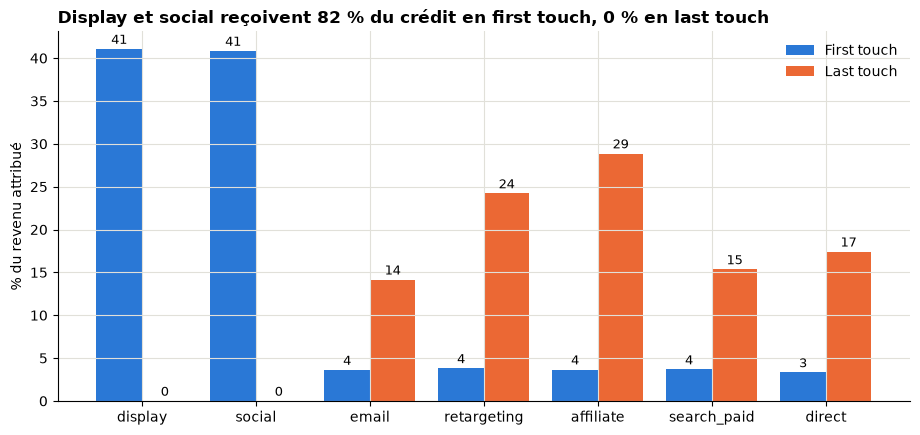

In [50]:
share = pandas.DataFrame({
    "First touch": first_touch_attribution["revenu attribué (%)"],
    "Last touch": last_touch_attribution["revenu attribué (%)"],
})
positions = numpy.arange(len(share))

figure, axis = matplotlib.pyplot.subplots(figsize=(11, 4.8))
axis.bar(positions - 0.2, share["First touch"], width=0.4, color=PRIMARY_COLOR, label="First touch")
axis.bar(positions + 0.2, share["Last touch"], width=0.4, color=ACCENT_COLOR, label="Last touch")
for position, (first, last) in enumerate(zip(share["First touch"], share["Last touch"])):
    axis.text(position - 0.2, first + 0.6, f"{first:.0f}", ha="center", fontsize=9)
    axis.text(position + 0.2, last + 0.6, f"{last:.0f}", ha="center", fontsize=9)
axis.set_xticks(positions, share.index)
axis.set_ylabel("% du revenu attribué")
axis.set_title("Display et social reçoivent 82 % du crédit en first touch, 0 % en last touch")
axis.legend(frameon=False)
matplotlib.pyplot.show()

### Analyse

- **Favorisés par le first touch** : display et social, qui concentrent plus de 80 % du crédit. **Favorisés par le last touch** : affiliation (29 %), retargeting (24 %), direct, search et email.
- **Si le CMO arbitrait sur le last touch seul**, display et social seraient jugés à 0 € de revenu et verraient leur budget coupé. Or ce sont eux qui alimentent les parcours : sans eux, il n'y a plus personne à retargeter ni à convertir en search. Ils seraient **sous-investis**, et l'effet apparaîtrait avec retard (moins de nouveaux parcours, donc moins de closing quelques semaines plus tard).
- **Symétriquement**, le first touch donnerait tout le mérite aux canaux de découverte et rien aux canaux de closing, alors que l'affiliation est le canal payant qui convertit le mieux.
- **C'est cohérent avec le rôle réel de chaque canal** : display et social font de la portée (CTR de 45 %, mais aucune vente directe), retargeting et email travaillent une audience déjà chaude, l'affiliation et le search captent l'intention. Les deux modèles ne se contredisent pas, ils regardent chacun une extrémité du parcours.

### Bonus : deux modèles multi-touch pour comparer

In [51]:
converting = converting.copy()
converting["journey_size"] = converting.groupby("journey_id").position.transform("size")
converting["rank_in_journey"] = converting.groupby("journey_id").cumcount()
converting["weight_linear"] = 1 / converting.journey_size
is_first = converting.rank_in_journey == 0
is_last = converting.rank_in_journey == converting.journey_size - 1
converting["weight_u"] = numpy.select(
    [converting.journey_size == 1, converting.journey_size == 2, is_first | is_last],
    [1.0, 0.5, 0.4],
    default=0.2 / (converting.journey_size - 2).clip(lower=1),
)
converting["journey_revenue"] = converting.journey_id.map(journey_revenue)

multi_touch = pandas.DataFrame({
    "First touch": share["First touch"],
    "Linéaire": (converting.weight_linear * converting.journey_revenue).groupby(converting.channel).sum(),
    "En U (40/20/40)": (converting.weight_u * converting.journey_revenue).groupby(converting.channel).sum(),
    "Last touch": share["Last touch"],
})
for column in ["Linéaire", "En U (40/20/40)"]:
    multi_touch[column] = multi_touch[column] / multi_touch[column].sum() * 100
multi_touch.reindex(CHANNEL_ORDER).round(1)

,First touch,Linéaire,En U (40/20/40),Last touch
channel,,,,
display,41.10,17.30,19.30,0.00
social,40.80,17.10,19.20,0.00
email,3.60,11.50,9.90,14.20
retargeting,3.80,14.60,14.20,24.20
affiliate,3.70,15.70,16.00,28.90
search_paid,3.70,11.80,10.40,15.30
direct,3.30,12.20,11.10,17.40


### Réflexion personnelle : et quand on ne peut pas comparer les canaux ?

Un auto-entrepreneur mesure chaque canal dans son propre outil : Meta Business Suite lui dira que ses publicités ont généré X ventes, Google Analytics attribuera les mêmes ventes au search, et son outil d'emailing les revendiquera aussi. Chaque outil fait du last touch de son point de vue, et la somme des ventes « attribuées » dépasse les ventes réelles. Dans ce cas, on ne peut raisonnablement conclure que deux choses : (1) la **tendance** d'un canal par rapport à lui-même dans le temps (son CPA monte ou baisse), et (2) ce qui se passe quand on **coupe** un canal quelques semaines (test d'incrémentalité). Comparer les canaux entre eux à partir de rapports séparés n'est pas possible, et il faut accepter de ne pas le faire plutôt que d'additionner des chiffres incompatibles.

### Recommandation : quel modèle d'attribution ?

**Un modèle multi-touch, de type position (en U), et pas un modèle unique.** Trois arguments tirés des données :

1. Les rôles sont tranchés : 80 % des parcours commencent par display ou social et aucun ne s'y termine. Tout modèle unique attribue 0 % à une moitié du parcours.
2. Les parcours sont longs (4 à 5 touchpoints en moyenne) : il y a de la place pour des contacts intermédiaires (email, retargeting) que ni le first ni le last ne voient.
3. Le modèle en U est lisible par un CMO : il donne la même importance à l'ouverture et à la fermeture, et un peu au milieu. Le linéaire, lui, dilue trop les extrémités.

Lecture budgétaire qui en découle : ne pas couper display et social malgré leur ROAS « nul », mais les piloter sur des KPIs de haut de parcours (coût par parcours initié, part de parcours convertis parmi ceux qu'ils ouvrent) ; renégocier l'affiliation (84 % du budget pour 29 % des conversions en last touch, 4 % en first touch, et un LTV:CAC de 1,8) ; et concentrer email et retargeting, quasi gratuits, sur les segments à risque et nouveaux du TP2 plutôt que sur toute la base.

---
# Synthèse pour le CMO

**Qui sont nos clients ?** 49 000 clients identifiés, à 91 % français, dont 23 % font 80 % du CA. Huit segments RFM, trois priorités : réactiver les **À risque** (valeur prouvée, inactifs depuis moins d'un an et demi), protéger les **Champions** (19 % de la base, 62 % du CA), convertir les **Nouveaux** au second achat (30 % de la base n'a jamais recommandé).

**Qu'est-ce qui marche ?** Les canaux pas chers (email, retargeting) affichent les meilleurs CPA et ROAS parce qu'ils récoltent une demande créée ailleurs : 87 % des conversions sont du réachat. Display et social ouvrent 80 % des parcours et n'en ferment aucun : invisibles en last touch, indispensables en réalité. L'affiliation absorbe 84 % du budget pour un quart des conversions.

**Que faire ?** Passer à une attribution en U pour arbitrer le budget ; sanctuariser display/social sur des KPIs de découverte ; renégocier l'affiliation ; réserver email et retargeting aux segments prioritaires ; avancer le budget sur mars-avril pour préparer le pic de printemps.

# Limites et confiance dans la data

- `customers.csv` est inexploitable pour les métriques agrégées : tout a été reconstruit depuis les transactions. Les 4 colonnes zero-party et le pays ont été conservés sans pouvoir être vérifiés.
- 22 % du CA est réalisé sans identifiant client : la segmentation ne voit pas ces acheteurs.
- La base est à 91 % française et mélange particuliers et revendeurs : les segments décrivent le client français, et les Champions contiennent une part de B2B non isolée faute de champ dédié.
- L'historique utile ne couvre que deux années (juillet 2024 → juin 2026) : la saisonnalité est observée deux fois, pas plus.
- Le revenu de `campaigns.csv` vaut 3,3 fois moins que celui des factures reliées, sans définition documentée : les niveaux de ROAS sont à prendre avec prudence, les classements sont robustes.
- Le primo-achat suggéré par le TP (via `customers.csv`) ne fonctionne pas ; il a été recalculé depuis la première facture observée.
- 25 % des parcours convertis n'ont pas leur touchpoint de position 1 dans l'export : le first touch est le premier contact *observé*.
- Toutes les relations montrées sont des corrélations. Aucun test d'incrémentalité n'a été mené : les recommandations budgétaires sont des hypothèses à tester (A/B test, coupure contrôlée d'un canal), pas des résultats démontrés.